# Zomato Restaurants — Predicting Aggregate Rating (End-to-End ML Project)

**Dataset:** `Zomato_Restaurant_Dataset.csv` · 9,551 restaurants · 15 countries · 21 columns

This notebook walks through a complete, leakage-safe machine-learning workflow:

| # | Section |
|---|---------|
| 1 | Problem statement |
| 2 | Proposed solution |
| 3 | Setup & data loading |
| 4 | Data-quality audit & deep cleaning |
| 5 | Exploratory data analysis (EDA) & visualisation |
| 6 | Train / test split (done *before* any learning) |
| 7 | Feature engineering with the underlying maths |
| 8 | Feature selection & dimensionality reduction |
| 9 | Scaling / normalisation |
| 10 | Machine-learning models & cross-validated comparison |
| 11 | Hyper-parameter tuning & ensembling |
| 12 | Under-fitting / over-fitting diagnostics |
| 13 | Data-leakage audit |
| 14 | Final evaluation on the untouched test set |
| 15 | Extension: classification of "highly rated" restaurants |
| 16 | Application: scoring un-rated restaurants (cold start) |
| 17 | Recommendations & solution summary |

> **Run order:** run all cells top to bottom (`Kernel → Restart & Run All`). Place `Zomato_Restaurant_Dataset.csv` next to this notebook. Set `QUICK_MODE = True` in the setup cell for a fast smoke-test run.

---
# 1. Problem Statement

## 1.1 Business context
On a restaurant-discovery platform, the **aggregate rating** is the single most visible quality signal. It drives search ranking, click-through, table bookings and orders. Two practical problems follow:

1. **Cold start.** A large share of listings (here **2,148 of 9,551 ≈ 22 %**) are marked *"Not rated"* (rating `0`). New restaurants cannot benefit from the rating signal, and the platform cannot rank or recommend them well.
2. **Drivers of quality are unclear.** Restaurant partners and the platform's account managers ask: *which listing attributes (price tier, cuisines, location, services like table booking / online delivery) go together with high ratings?*

## 1.2 Machine-learning formulation
| Item | Definition |
|---|---|
| **Primary task** | Supervised **regression**: predict `Aggregate rating` (range 1.8 – 4.9) of a restaurant from its listing attributes |
| **Training population** | Restaurants that *have* a rating (rating > 0). A rating of 0 means *"Not rated"* (every such row has ≤ 3 votes) — it is a **missing target**, not a genuinely terrible restaurant, so it is excluded from training and later *scored* by the model |
| **Secondary task** | **Classification**: is a restaurant *highly rated* (rating ≥ 4.0, i.e. Zomato's "Very Good" or "Excellent")? |
| **Two deployment scenarios** | **Scenario B – Cold-start model:** only attributes known at listing time (no votes). **Scenario A – Established-listing model:** additionally uses `Votes` (crowd engagement) |
| **Primary metric** | RMSE (penalises large misses), reported with **MAE** (average error in rating points) and **R²** |
| **Baseline to beat** | Predict the training mean for everyone (RMSE ≈ standard deviation of the rating ≈ 0.55) |

## 1.3 Success criteria
* Clearly beat the mean-baseline on **held-out** data.
* Small and explainable **train ↔ CV ↔ test** gap (no over-fitting) and error well below the baseline (no under-fitting).
* **No data leakage** — verified by explicit audits, not just assumed.
* Insights that a business user can act on.

## 1.4 Known data caveats (discovered during profiling)
* `Rating color` and `Rating text` are **deterministic re-labellings of the target** → pure leakage, must be removed.
* `Votes` is *co-produced* with the rating (people who vote also rate) → handled via two scenarios.
* Costs are in **12 different currency labels** → raw `Average Cost for two` is not comparable across countries.
* The currency label for the Philippines is wrong (*"Botswana Pula"*), 499 restaurants have coordinates `(0, 0)`, 18 have cost `0`, text-encoding is corrupted for 3 cities and the pound sign.
* ~91 % of rows are from India → results generalise best to India; other countries have few, probably **non-random** samples.

---
# 2. Proposed Solution

```
 raw CSV ──► audit & clean ──► split FIRST (80 % train / 20 % test, stratified by rating band)
                                         │
              ┌──────────────────────────┴───────────────────────────┐
              │  scikit-learn Pipeline  (every learned statistic is   │
              │  fitted ONLY on the training fold)                    │
              │                                                       │
              │  Feature builder  →  Target-encode / impute / scale   │
              │  (maths-based        (Bayesian shrinkage, median,     │
              │   features)           z-score)                        │
              │         →  optional feature reduction  →  model       │
              └──────────────────────────┬───────────────────────────┘
                                         │
     5-fold CV model zoo ─► tuning (randomised search) ─► convex blend of top models
                                         │
          diagnostics: learning curves · boosting-stage curves · train/CV/test gap
                                         │
          leakage audit: target-derived columns · naive-encoding demo · y-shuffle test ·
                         chain-grouped CV · near-duplicate check
                                         │
                      single look at the TEST set ─► recommendations
```

### Design principles that protect against leakage and over-fitting
1. **Split before you learn.** The 20 % test set is never touched until the final evaluation.
2. **Everything learned lives in the Pipeline.** Medians, country cost references, city centroids, cuisine vocabulary, target encodings, scalers and feature selectors are re-fitted inside every CV fold.
3. **Remove target look-alikes** (`Rating color`, `Rating text`) and administrative identifiers.
4. **Two scenarios** (with / without `Votes`) keep the model honest about what is known at prediction time.
5. **Regularised, cross-fitted encodings** for high-cardinality categories (city, locality) instead of raw target means.
6. **Independent checks:** shuffled-target test, chain-grouped CV, and a "naive-encoding" counter-example that shows what leakage *would* look like.

---
# 3. Data Loading

In [1]:
import os, re, math, time, warnings
from functools import partial

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.optimize import nnls
from scipy.stats import loguniform, randint, uniform

import sklearn
from sklearn import set_config
from sklearn.base import BaseEstimator, TransformerMixin, RegressorMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, RobustScaler, MinMaxScaler, TargetEncoder, PowerTransformer
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, SelectFromModel, mutual_info_regression
from sklearn.model_selection import (train_test_split, KFold, StratifiedKFold, GroupKFold,
                                     cross_validate, cross_val_score, cross_val_predict,
                                     RandomizedSearchCV, learning_curve)
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import RidgeCV, LassoCV, ElasticNetCV, Ridge, LogisticRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.ensemble import (RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor,
                              HistGradientBoostingRegressor, RandomForestClassifier,
                              HistGradientBoostingClassifier)
from sklearn.neural_network import MLPRegressor
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.metrics import (mean_absolute_error, r2_score, root_mean_squared_error, roc_auc_score,
                             average_precision_score, f1_score, precision_score, recall_score,
                             balanced_accuracy_score, brier_score_loss, confusion_matrix,
                             roc_curve, precision_recall_curve, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")                 # keep the notebook output readable
set_config(transform_output="pandas")             # transformers return DataFrames (keeps column names)

SEED = 42
np.random.seed(SEED)

In [2]:
# utf-8-sig removes the byte-order-mark the file starts with

raw = pd.read_csv("Zomato Restaurant Dataset.csv", encoding="utf-8-sig")

print("Shape:", raw.shape)

raw.head(3).T

Shape: (9551, 21)


,0,1,2
Restaurant ID,6317637,6304287,6300002
Restaurant Name,Le Petit Souffle,Izakaya Kikufuji,Heat - Edsa Shangri-La
Country Code,162,162,162
City,Makati City,Makati City,Mandaluyong City
Address,"Third Floor, Century City Mall, Kalayaan Avenu...","Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal..."
Locality,"Century City Mall, Poblacion, Makati City","Little Tokyo, Legaspi Village, Makati City","Edsa Shangri-La, Ortigas, Mandaluyong City"
Locality Verbose,"Century City Mall, Poblacion, Makati City, Mak...","Little Tokyo, Legaspi Village, Makati City, Ma...","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma..."
Longitude,121.027535,121.014101,121.056831
Latitude,14.565443,14.553708,14.581404
Cuisines,"French, Japanese, Desserts",Japanese,"Seafood, Asian, Filipino, Indian"


---
# 4. Data-Quality Audit & Deep Cleaning

Before touching the data we *measure* its problems. Every cleaning rule below is tied to evidence.

In [3]:
audit = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "n_missing": raw.isna().sum(),
    "pct_missing": raw.isna().mean() * 100,
    "n_unique": raw.nunique(),
})
display(audit)

print("\nFully duplicated rows        :", raw.duplicated().sum())
print("Duplicated Restaurant ID     :", raw["Restaurant ID"].duplicated().sum())
print("Rows with (lat, lon) = 0     :", ((raw["Latitude"] == 0) | (raw["Longitude"] == 0)).sum())
print("Rows with cost = 0           :", (raw["Average Cost for two"] == 0).sum())
print("Rows with rating = 0 (unrated):", (raw["Aggregate rating"] == 0).sum())
print("Max votes among unrated      :", raw.loc[raw["Aggregate rating"] == 0, "Votes"].max())
print("Min votes among rated        :", raw.loc[raw["Aggregate rating"] > 0, "Votes"].min())
print("\nCorrupted text (U+FFFD) in City:", raw["City"].str.contains("\ufffd").sum(),
      "| in Currency:", raw["Currency"].str.contains("\ufffd").sum())
print("\nNear-constant flags:")
for c in ["Is delivering now", "Switch to order menu"]:
    print(f"  {c:22s}", raw[c].value_counts().to_dict())

print("\nCountry ↔ currency label (as shipped in the file):")
display(raw.groupby("Country Code")["Currency"].agg(lambda s: s.iloc[0]).to_frame()
        .join(raw.groupby("Country Code")["City"].agg(lambda s: ", ".join(s.value_counts().index[:3]))))

,dtype,n_missing,pct_missing,n_unique
Restaurant ID,int64,0,0.000000,9551
Restaurant Name,object,0,0.000000,7446
Country Code,int64,0,0.000000,15
City,object,0,0.000000,141
Address,object,0,0.000000,8918
Locality,object,0,0.000000,1208
Locality Verbose,object,0,0.000000,1265
Longitude,float64,0,0.000000,8120
Latitude,float64,0,0.000000,8677
Cuisines,object,9,0.094231,1825



Fully duplicated rows        : 0
Duplicated Restaurant ID     : 0
Rows with (lat, lon) = 0     : 499
Rows with cost = 0           : 18
Rows with rating = 0 (unrated): 2148
Max votes among unrated      : 3
Min votes among rated        : 4

Corrupted text (U+FFFD) in City: 54 | in Currency: 80

Near-constant flags:
  Is delivering now      {'No': 9517, 'Yes': 34}
  Switch to order menu   {'No': 9551}

Country ↔ currency label (as shipped in the file):


,Currency,City
Country Code,,
1,Indian Rupees(Rs.),"New Delhi, Gurgaon, Noida"
14,Dollar($),"Hepburn Springs, Balingup, Armidale"
30,Brazilian Real(R$),"Bras�_lia, Rio de Janeiro, S��o Paulo"
37,Dollar($),"Chatham-Kent, Consort, Vineland Station"
94,Indonesian Rupiah(IDR),"Jakarta, Bogor, Tangerang"
148,NewZealand($),"Auckland, Wellington City"
162,Botswana Pula(P),"Mandaluyong City, Taguig City, Pasig City"
166,Qatari Rial(QR),Doha
184,Dollar($),Singapore


### 4.1 Cleaning decisions

| Finding | Action | Why |
|---|---|---|
| Column names contain spaces / capitals | Standardise to `snake_case` | Safer code |
| Corrupted characters in `City` (Brasília, São Paulo, İstanbul) and in the pound-sterling label | Repair with regex | Otherwise the same city can appear under inconsistent labels |
| `Currency` says "Botswana Pula" for country 162 although cities are Makati / Mandaluyong | Map `Country Code → Country, Currency` from the standard Zomato country-code table (Philippines → Peso) | Label error; the cost magnitude (~1,150) matches Philippine pesos |
| `Latitude/Longitude = 0` | Set to `NaN` (+ later a *missing* flag) | (0, 0) is in the Atlantic Ocean; it would corrupt every distance feature |
| Coordinates > 300 km away from their own city's median | Set to `NaN` | Geocoding errors |
| `Average Cost for two = 0` | Set to `NaN`, impute later *inside the pipeline* | A table for two cannot cost nothing |
| `Cuisines` missing (9 rows) | Label `Unknown` | Keep the rows |
| Yes/No columns | Map to 1/0 | Numeric |
| Duplicate listings (same name **and** address) | Drop duplicates | Would leak between train and test |
| `Rating color`, `Rating text` | **Drop** (leakage) | Deterministic functions of the target — proved below |
| `Restaurant ID`, `Address`, `Locality Verbose` | Drop | Identifier / free text / redundant with `Locality + City` |
| `Is delivering now`, `Switch to order menu` | Drop | Scrape-time snapshots (only 34 "Yes" and 0 "Yes") — not a property of the restaurant |
| Rating = 0 | Separate into an *unrated* set | Missing target, not a real score |

In [4]:
COUNTRY_MAP = {1: "India", 14: "Australia", 30: "Brazil", 37: "Canada", 94: "Indonesia",
               148: "New Zealand", 162: "Philippines", 166: "Qatar", 184: "Singapore",
               189: "South Africa", 191: "Sri Lanka", 208: "Turkey", 214: "UAE",
               215: "United Kingdom", 216: "United States"}
CURRENCY_MAP = {1: "INR", 14: "AUD", 30: "BRL", 37: "CAD", 94: "IDR", 148: "NZD", 162: "PHP",
                166: "QAR", 184: "SGD", 189: "ZAR", 191: "LKR", 208: "TRY", 214: "AED",
                215: "GBP", 216: "USD"}
GEO_MAX_KM = 300          # a restaurant further than this from its city's median point is a geocoding error


def haversine_km(lat1, lon1, lat2, lon2):
    """Great-circle distance (km) between two points on a sphere of radius R = 6371.0088 km.
       a = sin²(Δφ/2) + cos φ1 · cos φ2 · sin²(Δλ/2);   d = 2R · arcsin(√a)"""
    R = 6371.0088
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dphi, dlmb = p2 - p1, np.radians(lon2) - np.radians(lon1)
    a = np.sin(dphi / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dlmb / 2) ** 2
    return 2 * R * np.arcsin(np.sqrt(np.clip(a, 0, 1)))


def clean_data(df):
    """Return a cleaned copy + a log of what was changed."""
    log = {}
    d = df.copy()

    # 1) snake_case column names, trim whitespace in text
    d.columns = d.columns.str.strip().str.lower().str.replace(r"[^a-z0-9]+", "_", regex=True).str.strip("_")
    for c in d.columns:
        if pd.api.types.is_string_dtype(d[c]) or d[c].dtype == object:
            d[c] = d[c].str.strip()

    # 2) repair corrupted characters in city names
    before = d["city"].copy()
    d["city"] = (d["city"].str.replace(r"^Bras.{1,4}lia$", "Brasília", regex=True)
                         .str.replace(r"^S.{1,4}o Paulo$", "São Paulo", regex=True)
                         .str.replace(r"^.{1,4}stanbul$", "İstanbul", regex=True))
    log["city_names_repaired"] = int((before != d["city"]).sum())

    # 3) country / currency from the country code (fixes the wrong Philippines label)
    d["country"] = d["country_code"].map(COUNTRY_MAP)
    d["currency_clean"] = d["country_code"].map(CURRENCY_MAP)
    log["unmapped_country_codes"] = int(d["country"].isna().sum())

    # 4) Yes/No → 1/0
    for c in ["has_table_booking", "has_online_delivery", "is_delivering_now", "switch_to_order_menu"]:
        d[c] = d[c].map({"Yes": 1, "No": 0}).astype(int)

    # 5) coordinates: zeros and far-away points → NaN
    zero = (d["latitude"] == 0) | (d["longitude"] == 0)
    d.loc[zero, ["latitude", "longitude"]] = np.nan
    med = d.groupby("city")[["latitude", "longitude"]].transform("median")
    dist = haversine_km(d["latitude"], d["longitude"], med["latitude"], med["longitude"])
    far = dist > GEO_MAX_KM
    d.loc[far, ["latitude", "longitude"]] = np.nan
    log["coords_zero_set_nan"] = int(zero.sum())
    log["coords_far_set_nan"] = int(far.sum())

    # 6) impossible cost
    log["cost_zero_set_nan"] = int((d["average_cost_for_two"] == 0).sum())
    d["average_cost_for_two"] = d["average_cost_for_two"].replace(0, np.nan).astype(float)

    # 7) cuisines
    log["cuisines_filled_unknown"] = int(d["cuisines"].isna().sum())
    d["cuisines"] = d["cuisines"].fillna("Unknown")

    # 8) duplicate listings
    dup = d.duplicated(subset=["restaurant_name", "address"], keep="first")
    log["duplicate_listings_dropped"] = int(dup.sum())
    d = d.loc[~dup].reset_index(drop=True)
    return d, log


clean, clean_log = clean_data(raw)
print("Cleaning log:", clean_log)
print("Shape after cleaning:", clean.shape)

Cleaning log: {'city_names_repaired': 54, 'unmapped_country_codes': 0, 'coords_zero_set_nan': 499, 'coords_far_set_nan': 1, 'cost_zero_set_nan': 18, 'cuisines_filled_unknown': 9, 'duplicate_listings_dropped': 0}
Shape after cleaning: (9551, 23)


In [5]:
# --- Evidence that rating_text / rating_color are the TARGET in disguise --------------------------
chk = clean.groupby("rating_text")["aggregate_rating"].agg(["min", "max", "count"]).sort_values("min")
display(chk)
print("Rating bands do not overlap  →  rating_text is a deterministic function of aggregate_rating.")

ordinal = {"Not rated": 0, "Poor": 1, "Average": 2, "Good": 3, "Very Good": 4, "Excellent": 5}
band_means = clean.groupby("rating_text")["aggregate_rating"].transform("mean")
print(f"R² of predicting the rating from rating_text ALONE: {r2_score(clean['aggregate_rating'], band_means):.3f}"
      "  ← a 'model' that merely reads the answer key.")

# keep the leakage columns ONLY for the audit section later, then remove them from the modelling data
leak_audit = clean[["rating_text", "rating_color", "aggregate_rating"]].copy()

,min,max,count
rating_text,,,
Not rated,0.0,0.0,2148
Poor,1.8,2.4,186
Average,2.5,3.4,3737
Good,3.5,3.9,2100
Very Good,4.0,4.4,1079
Excellent,4.5,4.9,301


Rating bands do not overlap  →  rating_text is a deterministic function of aggregate_rating.
R² of predicting the rating from rating_text ALONE: 0.986  ← a 'model' that merely reads the answer key.


In [6]:
DROP_COLS = ["rating_color", "rating_text",                         # target look-alikes (leakage)
             "restaurant_id", "address", "locality_verbose",         # identifier / free text / redundant
             "is_delivering_now", "switch_to_order_menu",            # scrape-time snapshots
             "country_code", "currency", "currency_clean"]           # replaced by `country`
addr = clean[["restaurant_name", "address", "locality"]].copy()      # kept only for duplicate checks
model_df = clean.drop(columns=DROP_COLS)

FEATURE_COLS = ["restaurant_name", "country", "city", "locality", "longitude", "latitude", "cuisines",
                "average_cost_for_two", "has_table_booking", "has_online_delivery", "price_range", "votes"]
TARGET = "aggregate_rating"

rated   = model_df[model_df[TARGET] > 0].copy()       # supervised learning population
unrated = model_df[model_df[TARGET] == 0].copy()      # target is missing → scored later (cold start)
addr_rated = addr.loc[rated.index]

print(f"Rated   : {len(rated):,} rows  ({len(rated)/len(model_df):.1%})")
print(f"Unrated : {len(unrated):,} rows  ({len(unrated)/len(model_df):.1%})")
print("Columns kept for modelling:", FEATURE_COLS)
rated[FEATURE_COLS + [TARGET]].head()

Rated   : 7,403 rows  (77.5%)
Unrated : 2,148 rows  (22.5%)
Columns kept for modelling: ['restaurant_name', 'country', 'city', 'locality', 'longitude', 'latitude', 'cuisines', 'average_cost_for_two', 'has_table_booking', 'has_online_delivery', 'price_range', 'votes']


,restaurant_name,country,city,locality,longitude,latitude,cuisines,average_cost_for_two,has_table_booking,has_online_delivery,price_range,votes,aggregate_rating
0,Le Petit Souffle,Philippines,Makati City,"Century City Mall, Poblacion, Makati City",121.027535,14.565443,"French, Japanese, Desserts",1100.0,1,0,3,314,4.8
1,Izakaya Kikufuji,Philippines,Makati City,"Little Tokyo, Legaspi Village, Makati City",121.014101,14.553708,Japanese,1200.0,1,0,3,591,4.5
2,Heat - Edsa Shangri-La,Philippines,Mandaluyong City,"Edsa Shangri-La, Ortigas, Mandaluyong City",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",4000.0,1,0,4,270,4.4
3,Ooma,Philippines,Mandaluyong City,"SM Megamall, Ortigas, Mandaluyong City",121.056475,14.585318,"Japanese, Sushi",1500.0,0,0,4,365,4.9
4,Sambo Kojin,Philippines,Mandaluyong City,"SM Megamall, Ortigas, Mandaluyong City",121.057508,14.584450,"Japanese, Korean",1500.0,1,0,4,229,4.8


---
# 5. Exploratory Data Analysis (EDA) & Visualisation

EDA below uses the **rated** restaurants (the modelling population). Looking at the full data to *understand* it is fine; what we must avoid is *learning parameters* from the test rows — that happens only after the split in Section 6.

In [7]:
display(rated[["longitude", "latitude", "average_cost_for_two", "price_range", "votes", TARGET]].describe().T)
print("\nCategorical cardinality:")
print(rated[["restaurant_name", "country", "city", "locality", "cuisines"]].nunique().to_string())

,count,mean,std,min,25%,50%,75%,max
longitude,7188.0,65.336779,43.958905,-157.948486,77.088928,77.196258,77.278767,174.832089
latitude,7188.0,26.962232,10.475258,-41.330428,28.489963,28.572432,28.646170,55.976980
average_cost_for_two,7385.0,1451.945430,18325.680092,7.000000,300.000000,500.000000,800.000000,800000.000000
price_range,7403.0,1.970147,0.930611,1.000000,1.000000,2.000000,3.000000,4.000000
votes,7403.0,202.185060,479.195199,4.000000,19.000000,60.000000,181.000000,10934.000000
aggregate_rating,7403.0,3.440024,0.552195,1.800000,3.000000,3.400000,3.800000,4.900000



Categorical cardinality:
restaurant_name    5711
country              15
city                141
locality           1175
cuisines           1716


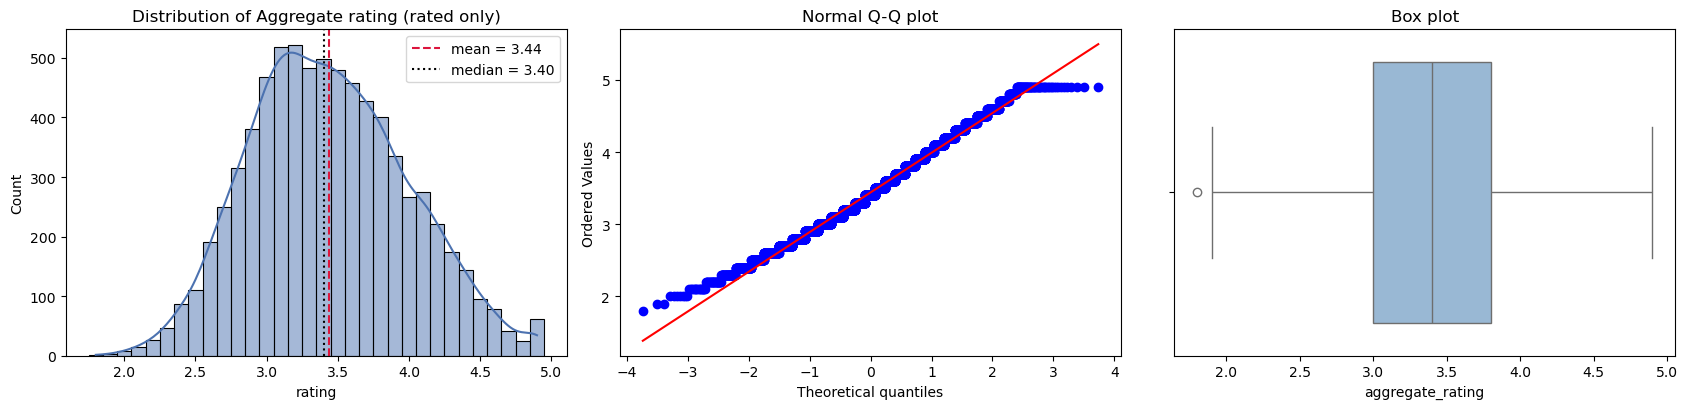

skewness = 0.231 | excess kurtosis = -0.337 | D'Agostino normality p-value = 1.06e-25
Ratings live on a 0.1 grid → only 32 distinct values; std = 0.552  (this is the RMSE of the 'predict the mean' baseline).


In [8]:
y_all = rated[TARGET]
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
sns.histplot(y_all, bins=np.arange(1.75, 5.0, 0.1), kde=True, ax=ax[0], color="#4C72B0")
ax[0].axvline(y_all.mean(), color="crimson", ls="--", label=f"mean = {y_all.mean():.2f}")
ax[0].axvline(y_all.median(), color="black", ls=":", label=f"median = {y_all.median():.2f}")
ax[0].set(title="Distribution of Aggregate rating (rated only)", xlabel="rating"); ax[0].legend()
stats.probplot(y_all, dist="norm", plot=ax[1]); ax[1].set_title("Normal Q-Q plot")
sns.boxplot(x=y_all, ax=ax[2], color="#8FB8DE"); ax[2].set_title("Box plot")
plt.tight_layout(); plt.show()

k2, p_norm = stats.normaltest(y_all)
print(f"skewness = {stats.skew(y_all):.3f} | excess kurtosis = {stats.kurtosis(y_all):.3f} | "
      f"D'Agostino normality p-value = {p_norm:.2e}")
print(f"Ratings live on a 0.1 grid → only {y_all.nunique()} distinct values; "
      f"std = {y_all.std():.3f}  (this is the RMSE of the 'predict the mean' baseline).")

> **💡 Takeaways.** Ratings are centred around 3.4 (mean 3.44, sd 0.55) and only mildly right-skewed, so no target transform is needed. The standard deviation, **0.55**, is the RMSE any model must beat.

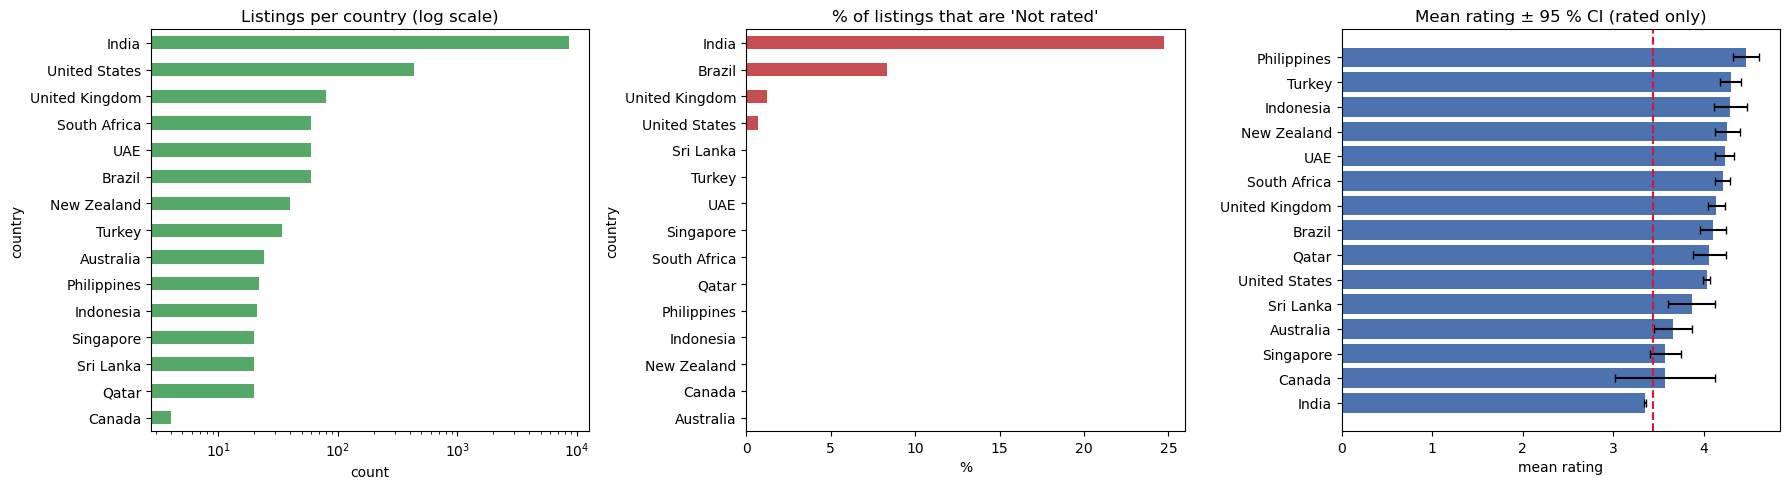

,count,mean,std,unrated_pct
country,,,,
India,6513,3.352034,0.504689,24.722607
Canada,4,3.575000,0.561991,0.000000
Singapore,20,3.575000,0.390512,0.000000
Australia,24,3.658333,0.523298,0.000000
Sri Lanka,20,3.870000,0.590361,0.000000
United States,431,4.032251,0.408974,0.691244
Qatar,20,4.060000,0.418519,0.000000
Brazil,55,4.105455,0.534172,8.333333
United Kingdom,79,4.139241,0.435130,1.250000


In [9]:
cn = model_df.groupby("country").agg(n_total=("country", "size"),
                                      unrated_pct=(TARGET, lambda s: (s == 0).mean() * 100))
rc = rated.groupby("country")[TARGET].agg(["mean", "std", "count"])
rc["ci95"] = 1.96 * rc["std"] / np.sqrt(rc["count"])
rc = rc.join(cn).sort_values("mean")

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
cn.sort_values("n_total").n_total.plot.barh(ax=ax[0], logx=True, color="#55A868")
ax[0].set(title="Listings per country (log scale)", xlabel="count")
cn.sort_values("unrated_pct").unrated_pct.plot.barh(ax=ax[1], color="#C44E52")
ax[1].set(title="% of listings that are 'Not rated'", xlabel="%")
ax[2].barh(rc.index, rc["mean"], xerr=rc["ci95"], color="#4C72B0", ecolor="black", capsize=3)
ax[2].axvline(rated[TARGET].mean(), color="crimson", ls="--")
ax[2].set(title="Mean rating ± 95 % CI (rated only)", xlabel="mean rating")
plt.tight_layout(); plt.show()
rc[["count", "mean", "std", "unrated_pct"]]

> **💡 Takeaways.** India holds ~91 % of the listings, has by far the highest share of *Not rated* restaurants (**≈ 25 %**; other countries 0–8 %) and the lowest average rating (3.35 vs 3.6–4.5 elsewhere). Non-Indian countries contribute only 4–55 rated restaurants each (except the US with 431), which suggests a **non-random, probably "best-of" sample**. Country is therefore informative for prediction but should not be read as "restaurants in country X are better".

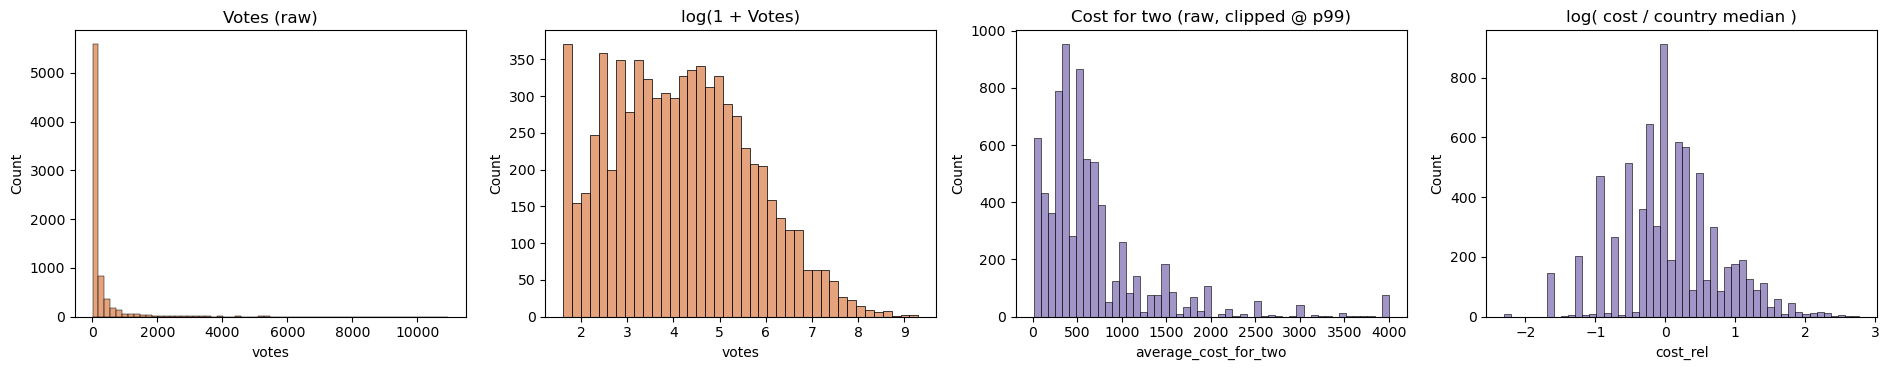

Spearman(raw cost, rating)               = +0.077   ← currencies are mixed, so the signal is diluted
Spearman(country-relative cost, rating)  = +0.274   ← motivates the feature 'relative cost'


In [10]:
rated_eda = rated.copy()
rated_eda["cost_rel"] = rated_eda["average_cost_for_two"] / rated_eda.groupby("country")["average_cost_for_two"].transform("median")

fig, ax = plt.subplots(1, 4, figsize=(19, 3.8))
sns.histplot(rated_eda["votes"], bins=60, ax=ax[0], color="#DD8452"); ax[0].set_title("Votes (raw)")
sns.histplot(np.log1p(rated_eda["votes"]), bins=40, ax=ax[1], color="#DD8452"); ax[1].set_title("log(1 + Votes)")
sns.histplot(rated_eda["average_cost_for_two"].clip(upper=rated_eda["average_cost_for_two"].quantile(.99)),
             bins=50, ax=ax[2], color="#8172B3"); ax[2].set_title("Cost for two (raw, clipped @ p99)")
sns.histplot(np.log(rated_eda["cost_rel"].dropna()), bins=50, ax=ax[3], color="#8172B3")
ax[3].set_title("log( cost / country median )")
plt.tight_layout(); plt.show()

rho_raw = stats.spearmanr(rated_eda["average_cost_for_two"].fillna(rated_eda["average_cost_for_two"].median()), rated_eda[TARGET])[0]
tmp = rated_eda.dropna(subset=["cost_rel"])
rho_rel = stats.spearmanr(tmp["cost_rel"], tmp[TARGET])[0]
print(f"Spearman(raw cost, rating)               = {rho_raw:+.3f}   ← currencies are mixed, so the signal is diluted")
print(f"Spearman(country-relative cost, rating)  = {rho_rel:+.3f}   ← motivates the feature 'relative cost'")

> **💡 Takeaways.** Votes are extremely right-skewed (skewness ≈ 8 → 0.3 after `log(1+x)`). Raw cost is dominated by currency (skewness ≈ 32); dividing by the country median gives a clean, symmetric price-level signal (Spearman with rating rises to **+0.27**).

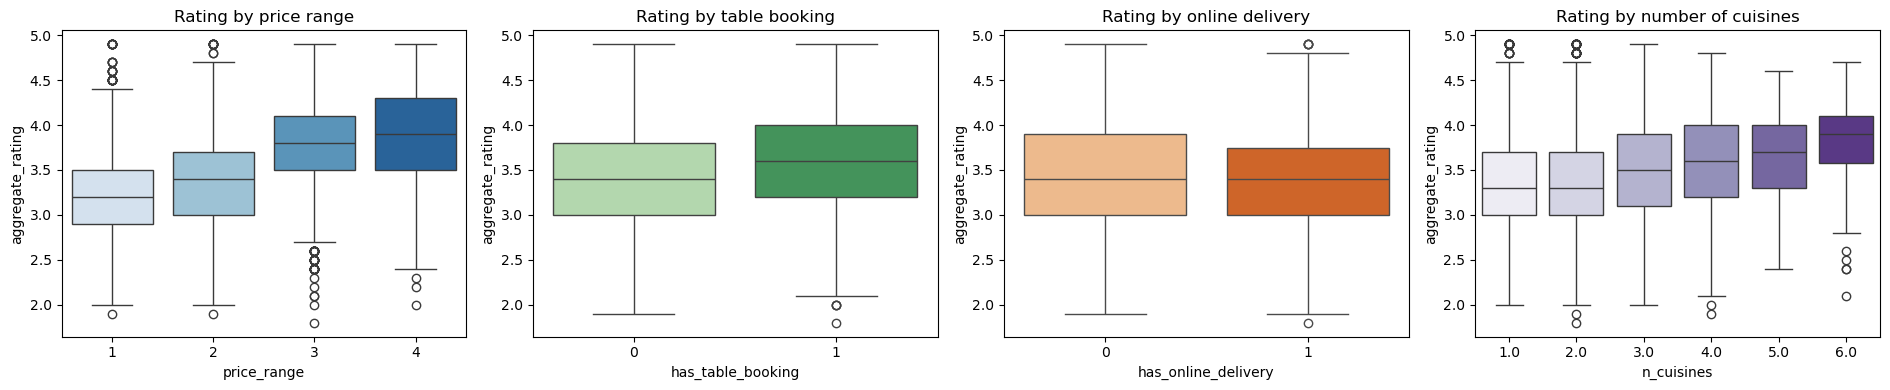

In [11]:
rated_eda["n_cuisines"] = rated_eda["cuisines"].replace("Unknown", np.nan).str.count(",").add(1).fillna(0)
fig, ax = plt.subplots(1, 4, figsize=(19, 4))
sns.boxplot(data=rated_eda, x="price_range", y=TARGET, ax=ax[0], palette="Blues"); ax[0].set_title("Rating by price range")
sns.boxplot(data=rated_eda, x="has_table_booking", y=TARGET, ax=ax[1], palette="Greens"); ax[1].set_title("Rating by table booking")
sns.boxplot(data=rated_eda, x="has_online_delivery", y=TARGET, ax=ax[2], palette="Oranges"); ax[2].set_title("Rating by online delivery")
sns.boxplot(data=rated_eda[rated_eda.n_cuisines.between(1, 6)], x="n_cuisines", y=TARGET, ax=ax[3], palette="Purples")
ax[3].set_title("Rating by number of cuisines")
plt.tight_layout(); plt.show()

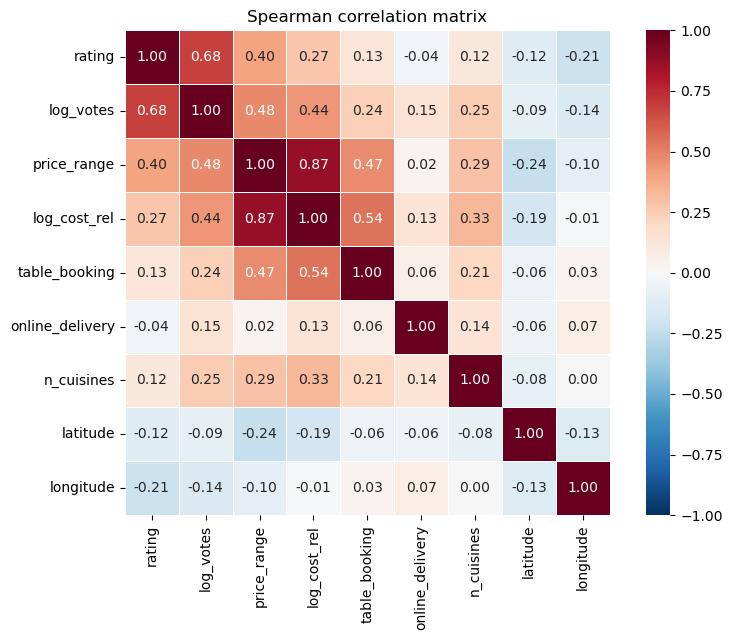

In [12]:
num_eda = pd.DataFrame({
    "rating": rated_eda[TARGET],
    "log_votes": np.log1p(rated_eda["votes"]),
    "price_range": rated_eda["price_range"],
    "log_cost_rel": np.log(rated_eda["cost_rel"]),
    "table_booking": rated_eda["has_table_booking"],
    "online_delivery": rated_eda["has_online_delivery"],
    "n_cuisines": rated_eda["n_cuisines"],
    "latitude": rated_eda["latitude"], "longitude": rated_eda["longitude"],
})
corr = num_eda.corr(method="spearman")
plt.figure(figsize=(8.5, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True, linewidths=.5)
plt.title("Spearman correlation matrix"); plt.tight_layout(); plt.show()

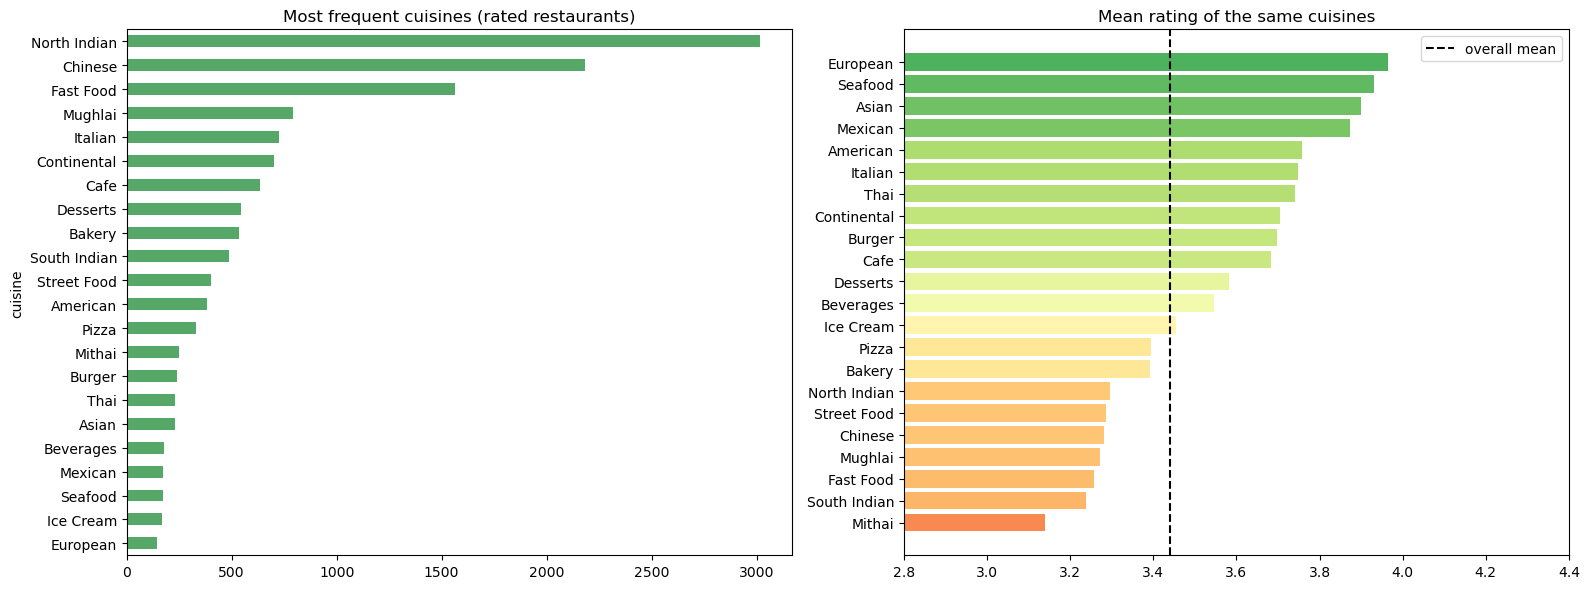

In [13]:
cu = rated.assign(cuisine=rated["cuisines"].str.split(", ")).explode("cuisine")
cs = (cu.groupby("cuisine")[TARGET].agg(["count", "mean"]).query("count >= 60")
        .sort_values("count", ascending=False).head(22))
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
cs["count"].sort_values().plot.barh(ax=ax[0], color="#55A868"); ax[0].set_title("Most frequent cuisines (rated restaurants)")
cs2 = cs.sort_values("mean")
ax[1].barh(cs2.index, cs2["mean"], color=plt.cm.RdYlGn((cs2["mean"] - 2.8) / 1.4))
ax[1].axvline(rated[TARGET].mean(), color="black", ls="--", label="overall mean"); ax[1].legend()
ax[1].set(title="Mean rating of the same cuisines", xlim=(2.8, 4.4))
plt.tight_layout(); plt.show()

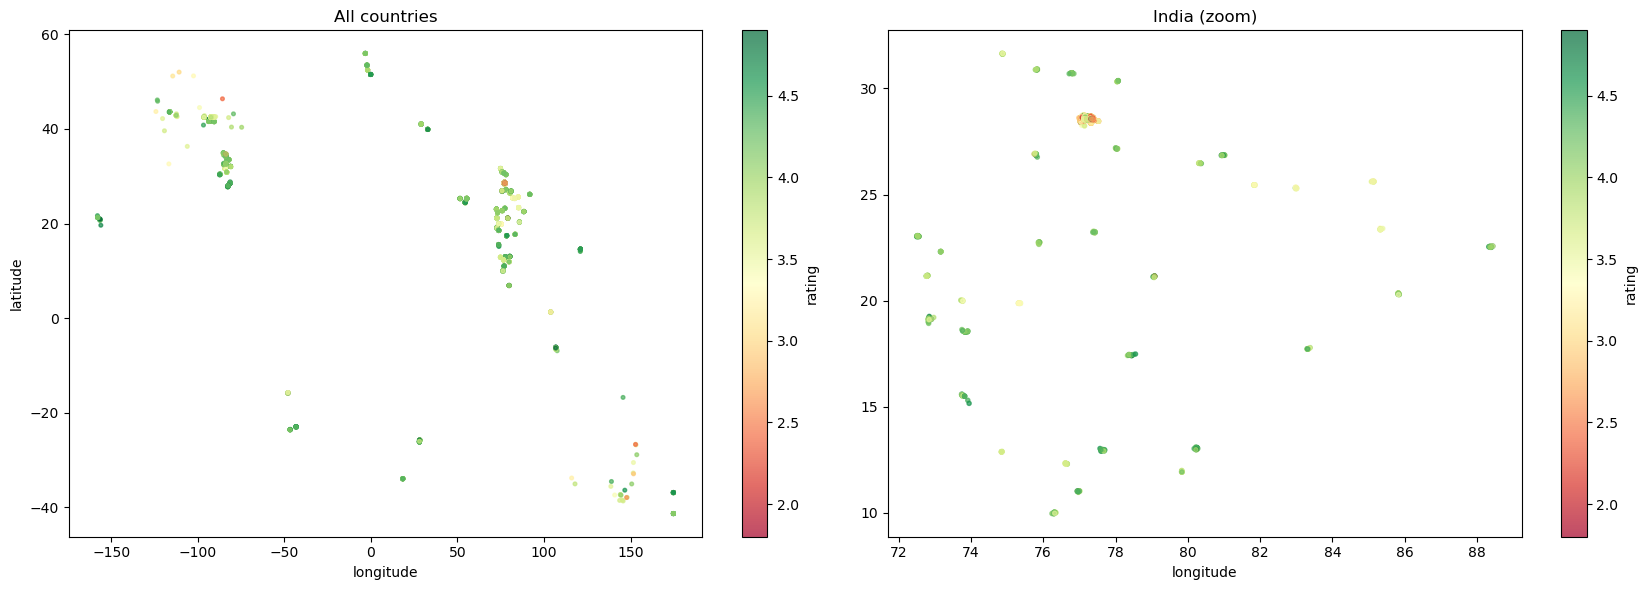

In [14]:
geo = rated.dropna(subset=["latitude", "longitude"])
fig, ax = plt.subplots(1, 2, figsize=(17, 6))
sc = ax[0].scatter(geo["longitude"], geo["latitude"], c=geo[TARGET], cmap="RdYlGn", s=7, alpha=.7)
ax[0].set(title="All countries", xlabel="longitude", ylabel="latitude"); plt.colorbar(sc, ax=ax[0], label="rating")
ind = geo[(geo["country"] == "India") & geo["longitude"].between(68, 90) & geo["latitude"].between(8, 36)]
sc = ax[1].scatter(ind["longitude"], ind["latitude"], c=ind[TARGET], cmap="RdYlGn", s=9, alpha=.7)
ax[1].set(title="India (zoom)", xlabel="longitude"); plt.colorbar(sc, ax=ax[1], label="rating")
plt.tight_layout(); plt.show()

In [15]:
# Formal statistical tests (non-parametric: the target is discrete and not normal)
rows = []
groups = [g[TARGET].values for _, g in rated.groupby("price_range")]
H, p = stats.kruskal(*groups); n, k = len(rated), len(groups)
rows.append(["price_range (4 levels)", "Kruskal–Wallis", H, p, f"ε² = {(H - k + 1) / (n - k):.3f}"])
for col in ["has_table_booking", "has_online_delivery"]:
    a = rated.loc[rated[col] == 1, TARGET]; b = rated.loc[rated[col] == 0, TARGET]
    U, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    rows.append([col, "Mann–Whitney U", U, p, f"rank-biserial r = {2 * U / (len(a) * len(b)) - 1:+.3f}"])
for name, s in [("votes", rated["votes"]), ("country-relative cost", rated_eda["cost_rel"])]:
    m = s.notna(); rho, p = stats.spearmanr(s[m], rated.loc[m, TARGET])
    rows.append([name, "Spearman ρ", rho, p, f"ρ = {rho:+.3f}"])
display(pd.DataFrame(rows, columns=["variable", "test", "statistic", "p-value", "effect size"]))

,variable,test,statistic,p-value,effect size
0,price_range (4 levels),Kruskal–Wallis,1.326067e+03,3.249781e-287,ε² = 0.179
1,has_table_booking,Mann–Whitney U,4.208234e+06,1.552683e-27,rank-biserial r = +0.204
2,has_online_delivery,Mann–Whitney U,5.659178e+06,8.662605e-04,rank-biserial r = -0.048
3,votes,Spearman ρ,6.821057e-01,0.000000e+00,ρ = +0.682
4,country-relative cost,Spearman ρ,2.735130e-01,7.458623e-127,ρ = +0.274


> **💡 Takeaways.** Price tier (ε² = 0.18), table booking (rank-biserial r = +0.20) and especially **votes (ρ = +0.68)** are strongly associated with rating. **Online delivery shows no positive association among rated restaurants** (r = −0.05) — the large raw gap seen on the full data came from un-rated restaurants rarely offering delivery.

In [16]:
# Is the price effect the same inside India and outside India? (guards against a Simpson's-paradox reading)
tbl = (rated.assign(region=np.where(rated["country"] == "India", "India", "Rest of world"))
            .pivot_table(index="price_range", columns="region", values=TARGET, aggfunc=["mean", "count"]))
display(tbl)
for col in ["has_table_booking", "has_online_delivery"]:
    display(rated.assign(region=np.where(rated["country"] == "India", "India", "Rest of world"))
                 .pivot_table(index=col, columns="region", values=TARGET, aggfunc="mean"))

mean               count              
region          India Rest of world India Rest of world
price_range                                            
1            3.196610      3.980405  2596           148
2            3.314338      3.998394  2462           249
3            3.678571      4.137966  1078           295
4            3.734748      4.188384   377           198

region,India,Rest of world
has_table_booking,,
0,3.313342,4.064413
1,3.550188,4.434043


region,India,Rest of world
has_online_delivery,,
0,3.340683,4.082947
1,3.372454,4.114286


> **💡 Takeaways.** The price-tier effect holds *inside* India (3.20 → 3.73) and *outside* it (3.98 → 4.19), and so does the table-booking effect (+0.24 in India, +0.37 elsewhere), so these are not artefacts of mixing countries. Online delivery moves the average by only ≈ +0.03 in both regions. The big level gap between India and the rest of the world is one more reason to give the model country/market information.

---
# 6. Train / Test Split — *before* any learning

We hold out **20 %** of the rated restaurants as a **test set that stays sealed until Section 14**.
The split is **stratified by rating band** so both parts have the same target distribution.

> Why now? Anything computed with the whole dataset — medians, encodings, scaling factors, selected features — would let information about the test rows seep into training. That is *data leakage*; it makes scores look better than reality.

In [17]:
X = rated[FEATURE_COLS].copy()
y = rated[TARGET].copy()
bands = pd.cut(y, bins=[0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0], labels=False)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=SEED, stratify=bands)
print(f"train: {X_train.shape}   test: {X_test.shape}")
print(pd.DataFrame({"train": y_train.describe(), "test": y_test.describe()}).T)
ks = stats.ks_2samp(y_train, y_test)
print(f"\nKS test train-vs-test target distribution: statistic={ks.statistic:.4f}, p={ks.pvalue:.3f}  (large p → same distribution)")

# --- Adversarial validation: can a model tell train rows from test rows? (AUC ≈ 0.5 means 'no'.)
adv_X = pd.concat([X_train, X_test])[["latitude", "longitude", "average_cost_for_two", "price_range",
                                      "votes", "has_table_booking", "has_online_delivery"]]
adv_y = np.r_[np.zeros(len(X_train)), np.ones(len(X_test))]
adv_auc = cross_val_score(HistGradientBoostingClassifier(max_iter=100, random_state=SEED), adv_X, adv_y,
                          cv=StratifiedKFold(3, shuffle=True, random_state=SEED), scoring="roc_auc").mean()
print(f"Adversarial-validation AUC = {adv_auc:.3f}")

cv = KFold(n_splits=5, shuffle=True, random_state=SEED)   # the CV splitter used everywhere below

train: (5922, 12)   test: (1481, 12)
        count      mean       std  min  25%  50%  75%  max
train  5922.0  3.440510  0.551360  1.8  3.0  3.4  3.8  4.9
test   1481.0  3.438082  0.555703  2.0  3.0  3.4  3.8  4.9

KS test train-vs-test target distribution: statistic=0.0089, p=1.000  (large p → same distribution)


  File "C:\Users\SKYTECH\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\SKYTECH\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\SKYTECH\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                        ^^^^^^^^^^^^^^^^^^^^^^
                        start_new_session, process_group)
                        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\SKYTECH\anaconda3\Lib\sub

Adversarial-validation AUC = 0.485


Adversarial-validation AUC = 0.485


> ** Takeaways.** Train and test targets are statistically indistinguishable (KS p ≈ 1.0) and adversarial validation gives AUC **0.49 ≈ 0.5**: a model cannot tell train rows from test rows, so the test set is a fair stand-in for unseen data.

---
# 7. Feature Engineering with the Underlying Maths

All feature construction lives inside **one custom scikit-learn transformer** (`RestaurantFeatureBuilder`). Its `fit` learns *target-free* statistics from the training fold only (medians, centroids, counts, vocabulary); its `transform` applies them to any data. This makes it impossible for validation or test rows to influence the features.

## 7.1 Currency-free price level — scale invariance
Costs sit in 12 currencies, so the raw number is meaningless across countries. For restaurant $i$ in country $c$ with cost $x_i$ let $m_c$ be the country median cost, and $\mu_c,\sigma_c$ the mean and standard deviation of $\ln x$ in that country. We build

$$\text{log\_cost\_ratio}_i=\ln\frac{x_i}{m_c}=\ln x_i-\ln m_c ,\qquad 
\text{cost\_z\_country}_i=\frac{\ln x_i-\mu_c}{\sigma_c}.$$

Both are **invariant to the currency**: if all prices of a country are multiplied by an exchange-rate factor $\kappa$, then $\ln\frac{\kappa x}{\kappa m}=\ln\frac{x}{m}$ and $\frac{\ln\kappa x-(\mu+\ln\kappa)}{\sigma}=\frac{\ln x-\mu}{\sigma}$. No exchange-rate table is needed. Missing costs are imputed with the training median of the (country, price-range) cell.

## 7.2 Skew-reducing power transforms
Votes and cost are right-skewed. With sample skewness $g_1=\frac{\frac1n\sum(x_i-\bar x)^3}{\left(\frac1n\sum(x_i-\bar x)^2\right)^{3/2}}$ a transform $T$ is good if $|g_1(T(x))|\approx0$. The **Box–Cox** family is 

$$T_\lambda(x)=\begin{cases}\dfrac{x^\lambda-1}{\lambda},&\lambda\ne0\\[4pt]\ln x,&\lambda=0\end{cases}$$

and **Yeo–Johnson** extends it to zeros/negatives. $\lambda$ is chosen by maximum likelihood. We compare them with $\ln(1+x)$ below and use $\ln(1+\text{votes})$ — nearly as good as the fitted $\lambda$, with no parameter to learn (so no leakage risk) and easy to explain.

## 7.3 Geography — haversine distance
Coordinates $(\varphi,\lambda)$ in radians; for a restaurant and its city's median point:

$$a=\sin^2\!\frac{\Delta\varphi}{2}+\cos\varphi_1\cos\varphi_2\sin^2\!\frac{\Delta\lambda}{2},\qquad d=2R\arcsin\sqrt a,\quad R=6371\text{ km}.$$

`log_dist_center_km = ln(1 + d)` measures how far a venue is from the city core (central / mall venues vs outskirts). Missing coordinates are filled with the city (then country) centroid and a `geo_missing` flag is added so the model can learn if "missingness" matters.

## 7.4 Market structure — frequency features with *leave-one-out* counts
`log_city_n`, `log_locality_n` (market size / density) and `log_chain_n` (how many other outlets share the restaurant's name → chain effect) are $\ln(1+n_{\text{others}})$.
A subtle trap: if a training row counts *itself*, but a new row cannot, the feature is distributed differently at training and prediction time (**train/serve skew**). We therefore use **leave-one-out** counts inside `fit_transform` (count − 1) and plain counts in `transform`.

## 7.5 Cuisine information content
Let $p(c)$ be the share of training restaurants serving cuisine $c$. Its **self-information (surprisal)** is $I(c)=-\log_2 p(c)$ bits: rare cuisines carry more information. For restaurant $i$ with cuisine set $S_i$:

$$\text{mean\_surprisal}_i=\frac1{|S_i|}\sum_{c\in S_i}I(c),\qquad \text{max\_surprisal}_i=\max_{c\in S_i}I(c).$$

We also add `n_cuisines` and a multi-hot encoding of the 25 most frequent cuisines.

## 7.6 High-cardinality categories — Bayesian-shrinkage target encoding
`country` (15), `city` (141) and `locality` (≈1,200) are encoded by the **posterior mean** of the rating in the category. With $n_k$ restaurants in category $k$, category mean $\bar y_k$ and global mean $\bar y$:

$$\hat\mu_k=\lambda_k\,\bar y_k+(1-\lambda_k)\,\bar y,\qquad \lambda_k=\frac{n_k}{n_k+m}.$$

Small categories are *shrunk* toward the global mean (their own mean is mostly noise), large ones keep their own mean. scikit-learn's `TargetEncoder(smooth="auto")` picks $m$ by empirical Bayes ($m=\sigma^2_{\text{within}}/\tau^2_{\text{between}}$) and, crucially, uses **5-fold cross-fitting** during training: each row is encoded with statistics computed on *other* folds, so a row's own target never enters its own feature.

## 7.7 Interactions
`price_x_india` = price tier × India flag (the price effect differs inside / outside India — see EDA) and `booking_x_price`.

In [18]:
class RestaurantFeatureBuilder(TransformerMixin, BaseEstimator):
    """Builds all engineered features. `fit` learns TARGET-FREE statistics from the training data only."""
    CAT_COLS = ["country", "city", "locality"]          # encoded later (target encoding, cross-fitted)

    def __init__(self, use_votes=True, top_k_cuisines=25, chain_min=3):
        self.use_votes = use_votes
        self.top_k_cuisines = top_k_cuisines
        self.chain_min = chain_min

    # ------------------------------------------------------------------ learn from TRAIN only
    def fit(self, X, y=None):
        cost = X["average_cost_for_two"].astype(float)
        self.global_cost_med_ = cost.median()
        self.country_cost_med_ = cost.groupby(X["country"]).median()
        self.cost_med_cp_ = cost.groupby([X["country"], X["price_range"]]).median()
        logc = np.log(cost.where(cost > 0))
        self.global_logc_mu_, self.global_logc_sd_ = logc.mean(), logc.std()
        g = logc.groupby(X["country"])
        self.country_logc_mu_ = g.mean()
        self.country_logc_sd_ = g.std().fillna(self.global_logc_sd_).clip(lower=1e-3)

        ok = X["latitude"].notna() & X["longitude"].notna()
        coords = X.loc[ok, ["latitude", "longitude"]]
        self.city_centroid_ = coords.groupby(X.loc[ok, "city"]).median()
        self.country_centroid_ = coords.groupby(X.loc[ok, "country"]).median()
        self.global_centroid_ = coords.median()

        self.city_n_ = X["city"].value_counts()
        self.loc_n_ = (X["city"] + "|" + X["locality"]).value_counts()
        self.name_n_ = X["restaurant_name"].str.lower().value_counts()

        s = X["cuisines"].replace("Unknown", np.nan)
        D = s.str.get_dummies(sep=", ")
        n = len(X)
        counts = D.sum()
        self.cuisine_surprisal_ = -np.log2(counts / n)           # I(c) = -log2 p(c)
        self.max_surprisal_ = -np.log2(1.0 / n)
        self.top_cuisines_ = list(counts.nlargest(self.top_k_cuisines).index)
        return self

    # ------------------------------------------------------------------ apply learned statistics
    def _build(self, X, loo):
        off = 1 if loo else 0                                    # leave-one-out for training rows
        out = pd.DataFrame(index=X.index)
        for c in self.CAT_COLS:
            out[c] = X[c].astype(object)

        # 7.1 currency-free price level
        cost = X["average_cost_for_two"].astype(float)
        key = pd.MultiIndex.from_arrays([X["country"], X["price_range"]])
        fill = pd.Series(self.cost_med_cp_.reindex(key).to_numpy(), index=X.index)
        fill = fill.fillna(X["country"].map(self.country_cost_med_)).fillna(self.global_cost_med_)
        lc = np.log(cost.fillna(fill))
        mu = X["country"].map(self.country_logc_mu_).fillna(self.global_logc_mu_)
        sd = X["country"].map(self.country_logc_sd_).fillna(self.global_logc_sd_)
        med = X["country"].map(self.country_cost_med_).fillna(self.global_cost_med_)
        out["cost_missing"] = cost.isna().astype(float)
        out["cost_z_country"] = (lc - mu) / sd
        out["log_cost_ratio"] = lc - np.log(med)

        # 7.3 geography
        lat, lon = X["latitude"].astype(float), X["longitude"].astype(float)
        c_lat = (X["city"].map(self.city_centroid_["latitude"])
                 .fillna(X["country"].map(self.country_centroid_["latitude"]))
                 .fillna(self.global_centroid_["latitude"]))
        c_lon = (X["city"].map(self.city_centroid_["longitude"])
                 .fillna(X["country"].map(self.country_centroid_["longitude"]))
                 .fillna(self.global_centroid_["longitude"]))
        out["geo_missing"] = (lat.isna() | lon.isna()).astype(float)
        out["latitude"], out["longitude"] = lat.fillna(c_lat), lon.fillna(c_lon)
        out["log_dist_center_km"] = np.log1p(haversine_km(lat, lon, c_lat, c_lon))   # NaN if coords missing → imputed later

        # 7.4 market structure (leave-one-out counts)
        out["log_city_n"] = np.log1p((X["city"].map(self.city_n_).fillna(0) - off).clip(lower=0))
        out["log_locality_n"] = np.log1p(((X["city"] + "|" + X["locality"]).map(self.loc_n_).fillna(0) - off).clip(lower=0))
        chain_n = (X["restaurant_name"].str.lower().map(self.name_n_).fillna(0) - off).clip(lower=0)
        out["log_chain_n"] = np.log1p(chain_n)
        out["is_chain"] = ((chain_n + 1) >= self.chain_min).astype(float)

        # 7.5 cuisines
        s = X["cuisines"].replace("Unknown", np.nan)
        D = s.str.get_dummies(sep=", ")
        n_c = D.sum(axis=1).astype(float)
        Iv = pd.Series(D.columns, index=D.columns).map(self.cuisine_surprisal_).fillna(self.max_surprisal_).to_numpy(float)
        Dn = D.to_numpy(float)
        out["n_cuisines"] = n_c
        out["mean_surprisal"] = np.where(n_c > 0, (Dn @ Iv) / np.maximum(n_c, 1), np.nan)
        out["max_surprisal"] = np.where(n_c > 0, (Dn * Iv).max(axis=1), np.nan)
        for c in self.top_cuisines_:
            out["cuis_" + re.sub(r"\W+", "_", c)] = D[c].astype(float) if c in D.columns else 0.0

        # plain attributes + interactions
        out["price_range"] = X["price_range"].astype(float)
        out["has_table_booking"] = X["has_table_booking"].astype(float)
        out["has_online_delivery"] = X["has_online_delivery"].astype(float)
        out["is_india"] = (X["country"] == "India").astype(float)
        out["price_x_india"] = out["price_range"] * out["is_india"]
        out["booking_x_price"] = out["has_table_booking"] * out["price_range"]
        if self.use_votes:                                       # Scenario A only
            out["log_votes"] = np.log1p(X["votes"].astype(float))
        return out

    def fit_transform(self, X, y=None):                          # training rows → leave-one-out counts
        return self.fit(X, y)._build(X, loo=True)

    def transform(self, X):                                      # new rows → plain counts
        return self._build(X, loo=False)


class CorrelationFilter(TransformerMixin, BaseEstimator):
    """Drops one column of every pair with |Pearson r| > threshold (learned on the training fold only)."""
    def __init__(self, threshold=0.95):
        self.threshold = threshold

    def fit(self, X, y=None):
        c = pd.DataFrame(X).corr().abs().to_numpy()
        upper = np.triu(c, k=1)
        drop = {j for j in range(c.shape[1]) if (upper[:, j] > self.threshold).any()}
        self.keep_idx_ = [j for j in range(c.shape[1]) if j not in drop]
        return self

    def transform(self, X):
        return X.iloc[:, self.keep_idx_] if isinstance(X, pd.DataFrame) else np.asarray(X)[:, self.keep_idx_]


def make_scaler(kind):
    return {"standard": StandardScaler(), "robust": RobustScaler(),
            "minmax": MinMaxScaler(), "none": "passthrough"}[kind]


def build_steps(*, use_votes, scaler="standard", reduce=None, cuisine_pca=None, task="reg"):
    """feature builder → (target-encode + impute + scale) → optional reduction"""
    te = TargetEncoder(target_type="continuous" if task == "reg" else "binary",
                       smooth="auto", cv=5, random_state=SEED)              # cross-fitted, shrinkage encoding
    cat_pipe = Pipeline([("te", te), ("scale", make_scaler(scaler))])
    num_pipe = Pipeline([("imp", SimpleImputer(strategy="median")), ("scale", make_scaler(scaler))])
    num_sel = make_column_selector(pattern="^(?!cuis_)", dtype_include=np.number)   # all numeric except cuisine flags
    cuis_sel = make_column_selector(pattern="^cuis_")
    parts = [("cat", cat_pipe, RestaurantFeatureBuilder.CAT_COLS), ("num", num_pipe, num_sel),
             ("cuis", PCA(n_components=cuisine_pca, random_state=SEED) if cuisine_pca else "passthrough", cuis_sel)]
    prep = ColumnTransformer(parts, remainder="drop", verbose_feature_names_out=False)
    steps = [("fe", RestaurantFeatureBuilder(use_votes=use_votes)), ("prep", prep)]
    if reduce == "corr":
        steps.append(("reduce", CorrelationFilter(0.95)))
    elif reduce == "mi":
        steps.append(("reduce", SelectKBest(partial(mutual_info_regression, random_state=SEED), k=30)))
    elif reduce == "lasso":
        # Lasso is scale-dependent, so it gets its own internal standardisation (works for tree pipelines too)
        lasso_sel = Pipeline([("s", StandardScaler()), ("l", LassoCV(cv=3, max_iter=5000, random_state=SEED))])
        steps.append(("reduce", SelectFromModel(lasso_sel, importance_getter="named_steps.l.coef_", threshold=1e-6)))
    return steps


def build_pipeline(model, **kw):
    return Pipeline(build_steps(**kw) + [("model", model)])


def build_preprocessor(**kw):
    return Pipeline(build_steps(**kw))

print("Feature builder + pipeline factory defined.")

Feature builder + pipeline factory defined.


In [19]:
fe_demo = RestaurantFeatureBuilder(use_votes=True)
F_train = fe_demo.fit_transform(X_train, y_train)          # fitted on TRAIN only
print("Engineered feature matrix (train):", F_train.shape)
F_train.drop(columns=RestaurantFeatureBuilder.CAT_COLS).filter(regex="^(?!cuis_)").head(8)

Engineered feature matrix (train): (5922, 49)


,cost_missing,cost_z_country,log_cost_ratio,geo_missing,latitude,longitude,log_dist_center_km,log_city_n,log_locality_n,log_chain_n,...,n_cuisines,mean_surprisal,max_surprisal,price_range,has_table_booking,has_online_delivery,is_india,price_x_india,booking_x_price,log_votes
2687,0.0,-0.120423,0.000000,0.0,28.668945,77.101544,2.502382,8.078998,0.000000,2.564949,...,5.0,2.836969,4.917159,2.0,0.0,0.0,1.0,2.0,0.0,4.770685
5453,0.0,-0.120423,0.000000,0.0,28.706859,77.190708,2.281677,8.078998,2.890372,1.098612,...,1.0,1.787876,1.787876,2.0,0.0,0.0,1.0,2.0,0.0,4.663439
5903,0.0,-0.614216,-0.356675,0.0,28.570947,77.266841,2.273031,8.078998,3.218876,2.079442,...,3.0,3.283753,3.803948,1.0,0.0,1.0,1.0,1.0,0.0,4.488636
5029,0.0,0.839195,0.693147,0.0,28.549335,77.127798,2.547289,8.078998,2.833213,0.000000,...,3.0,2.336926,3.928242,3.0,1.0,0.0,1.0,3.0,3.0,2.079442
2254,0.0,0.131990,0.182322,0.0,28.508826,77.031015,2.039672,6.553933,1.791759,0.000000,...,2.0,1.541267,1.787876,2.0,0.0,0.0,1.0,2.0,0.0,2.772589
5771,0.0,-0.827627,-0.510826,0.0,28.623847,77.155619,1.801210,8.078998,3.044522,0.000000,...,1.0,2.256908,2.256908,1.0,0.0,1.0,1.0,1.0,0.0,2.397895
100,0.0,-1.356823,-0.916291,0.0,31.598500,-84.175700,1.444732,2.708050,2.639057,0.000000,...,2.0,3.960112,4.515060,1.0,0.0,0.0,0.0,0.0,0.0,4.770685
1147,0.0,1.305019,1.029619,0.0,15.561295,73.749478,1.200405,2.639057,0.693147,0.000000,...,4.0,2.975830,5.423344,4.0,0.0,0.0,1.0,4.0,0.0,7.692570


In [20]:
# ---- 7.2  Skewness before / after transforms --------------------------------------------------------
v = X_train["votes"].astype(float)
c = X_train["average_cost_for_two"].dropna().astype(float)
bc_v, lam_bc = stats.boxcox(v + 1);   yj_v, lam_yj = stats.yeojohnson(v)
res = pd.DataFrame({
    "votes": {"raw": stats.skew(v), "sqrt": stats.skew(np.sqrt(v)), "log(1+x)": stats.skew(np.log1p(v)),
              f"Box-Cox (λ={lam_bc:.2f})": stats.skew(bc_v), f"Yeo-Johnson (λ={lam_yj:.2f})": stats.skew(yj_v)}
}).T
print("Skewness g1 of votes:"); display(res.T)
print(f"Cost skewness: raw = {stats.skew(c):.2f}  |  ln(cost) = {stats.skew(np.log(c)):.2f}  |  "
      f"cost_z_country = {stats.skew(F_train['cost_z_country']):.2f}  |  log_cost_ratio = {stats.skew(F_train['log_cost_ratio']):.2f}")

# ---- 7.3  Haversine sanity check:  New Delhi → Mumbai ≈ 1,150 km ---------------------------------------
print(f"\nHaversine(New Delhi, Mumbai) = {haversine_km(28.6139, 77.2090, 19.0760, 72.8777):,.0f} km  (reference ≈ 1,150 km)")
print(f"Haversine(0°, 0°  → 0°, 1°)  = {haversine_km(0, 0, 0, 1):.1f} km  (1° of longitude at the equator ≈ 111.2 km)")

Skewness g1 of votes:


,votes
raw,7.968862
sqrt,2.528681
log(1+x),0.299517
Box-Cox (λ=-0.09),0.035345
Yeo-Johnson (λ=-0.09),0.035345


Cost skewness: raw = 31.86  |  ln(cost) = -0.61  |  cost_z_country = 0.15  |  log_cost_ratio = 0.17

Haversine(New Delhi, Mumbai) = 1,148 km  (reference ≈ 1,150 km)
Haversine(0°, 0°  → 0°, 1°)  = 111.2 km  (1° of longitude at the equator ≈ 111.2 km)


In [21]:
# ---- 7.5  Cuisine information content -------------------------------------------------------------------
I = fe_demo.cuisine_surprisal_.sort_values()
q = np.exp2(-I) / np.exp2(-I).sum()                         # distribution over cuisine tokens
H = -(q * np.log2(q)).sum()
print(f"Shannon entropy of the cuisine distribution: H = {H:.2f} bits   (maximum possible log2({len(q)}) = {np.log2(len(q)):.2f} bits)")
print("Interpretation: a few cuisines dominate (North Indian, Chinese, Fast Food) → the distribution is far from uniform.\n")
display(pd.concat([I.head(5).rename("surprisal (bits)"), I.tail(5).rename("surprisal (bits)")]).to_frame())
rho = stats.spearmanr(F_train["mean_surprisal"].fillna(F_train["mean_surprisal"].median()), y_train)[0]
print(f"Spearman(mean_surprisal, rating) = {rho:+.3f}")

# ---- 7.6  Shrinkage target encoding: raw mean vs fixed-m shrinkage vs sklearn 'auto' ----------------------
g_mean, M_FIXED = y_train.mean(), 10
city_stats = y_train.groupby(X_train["city"]).agg(["count", "mean"])
city_stats["λ (m=10)"] = city_stats["count"] / (city_stats["count"] + M_FIXED)
city_stats["shrunk (m=10)"] = city_stats["λ (m=10)"] * city_stats["mean"] + (1 - city_stats["λ (m=10)"]) * g_mean
te_demo = TargetEncoder(target_type="continuous", smooth="auto", cv=5, random_state=SEED).fit(X_train[["city"]], y_train)
city_stats["sklearn auto"] = pd.Series(te_demo.encodings_[0], index=te_demo.categories_[0])
print(f"global mean = {g_mean:.3f}.  Small cities are pulled toward it:")
display(city_stats[city_stats["count"].between(2, 12)].sort_values("count").head(8).rename(columns={"mean": "raw mean"}))

Shannon entropy of the cuisine distribution: H = 4.68 bits   (maximum possible log2(135) = 7.08 bits)
Interpretation: a few cuisines dominate (North Indian, Chinese, Fast Food) → the distribution is far from uniform.



,surprisal (bits)
North Indian,1.294659
Chinese,1.787876
Fast Food,2.256908
Mughlai,3.216719
Continental,3.397442
Peruvian,12.531869
Soul Food,12.531869
Malwani,12.531869
Durban,12.531869
Gourmet Fast Food,12.531869


Spearman(mean_surprisal, rating) = +0.406
global mean = 3.441.  Small cities are pulled toward it:


,count,raw mean,λ (m=10),shrunk (m=10),sklearn auto
city,,,,,
Bogor,2,3.850000,0.166667,3.508758,3.835384
Inner City,2,4.900000,0.166667,3.683758,4.900000
San Juan City,2,4.250000,0.166667,3.575425,4.246685
Pasay City,3,4.366667,0.230769,3.654238,4.236667
Pasig City,3,4.633333,0.230769,3.715777,4.520189
Mandaluyong City,3,4.700000,0.230769,3.731162,4.638679
Taguig City,4,4.525000,0.285714,3.750364,4.514510
Johannesburg,6,4.200000,0.375000,3.725319,4.189054


> **Takeaways.** The cuisine distribution is far from uniform (entropy 4.7 of a possible 7.1 bits): three cuisines cover most restaurants. **Rarer cuisine mixes go with higher ratings** (Spearman of mean surprisal with rating = +0.41) — a feature that raw one-hot columns capture only indirectly. The table also shows why shrinkage matters: a city with 2 restaurants and a raw mean of 4.9 is pulled to ≈ 3.7 under fixed-m shrinkage, whereas scikit-learn's empirical-Bayes `auto` setting trusts it more (4.9) because between-city variance is large relative to within-city noise.

---
# 8. Feature Selection & Dimensionality Reduction

The feature builder produces ~45 columns for ~5,900 training rows — not a "curse-of-dimensionality" regime, but redundant features still hurt linear models (variance inflation) and interpretability. We examine redundancy with four independent lenses (all computed on the **training set only**):

* **Variance / prevalence** – near-constant columns carry no information.
* **Correlation & VIF.** For feature $j$, $\text{VIF}_j=\dfrac1{1-R_j^2}=\big[R^{-1}\big]_{jj}$ where $R$ is the correlation matrix and $R_j^2$ is the $R^2$ from regressing feature $j$ on all the others. $\text{VIF}>10$ means severe collinearity.
* **Mutual information** (non-linear relevance): $I(X;Y)=\iint p(x,y)\ln\frac{p(x,y)}{p(x)p(y)}\,dx\,dy$ — estimated with a k-NN estimator.
* **Lasso (L1) path**: $\min_\beta \frac1{2n}\lVert y-X\beta\rVert_2^2+\alpha\lVert\beta\rVert_1$ drives uninformative coefficients exactly to 0.

For the 25 multi-hot cuisine columns we also test **PCA via SVD**: for the centred matrix $X_c=U\Sigma V^\top$ the variance explained by component $i$ is $\sigma_i^2/\sum_j\sigma_j^2$.

Finally, each reduction strategy is judged by **cross-validated RMSE with the selection step inside the pipeline** — selecting features on the full training set and *then* cross-validating would itself be a (subtle) leakage.

Model matrix after encoding / imputation / scaling: (5922, 49)

Rarest cuisine flags (share of restaurants):


,prevalence
cuis_Japanese,0.017562
cuis_Healthy_Food,0.017562
cuis_Biryani,0.018237
cuis_European,0.020770
cuis_Ice_Cream,0.022796


Most correlated feature pairs (|r|):


,,|r|
cost_z_country,log_cost_ratio,0.995273
country,is_india,0.977321
has_table_booking,booking_x_price,0.972936
mean_surprisal,max_surprisal,0.903640
log_chain_n,is_chain,0.879481
cost_z_country,price_range,0.836929
log_cost_ratio,price_range,0.824389
city,log_city_n,0.774639


Variance-inflation factors (top 8):


,VIF
log_cost_ratio,291.472264
cost_z_country,279.687946
is_india,44.190472
country,28.167578
booking_x_price,24.338127
price_x_india,21.808536
has_table_booking,21.661223
price_range,15.982701


LassoCV: best alpha = 0.00036 → keeps 44 of 49 features


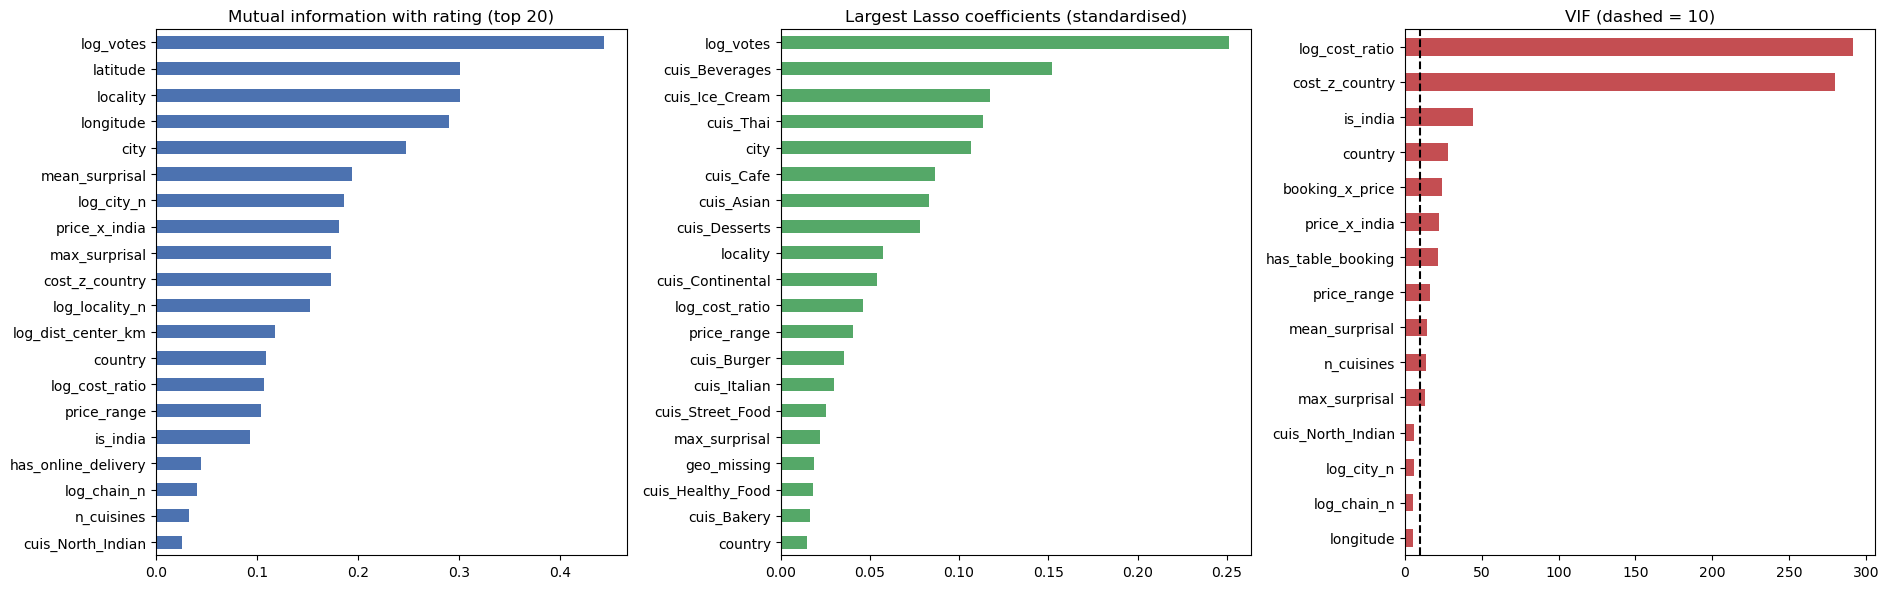

In [22]:
prep_probe = build_preprocessor(use_votes=True, scaler="standard")
Z_train = prep_probe.fit_transform(X_train, y_train)
print("Model matrix after encoding / imputation / scaling:", Z_train.shape)

# -- (a) prevalence of the cuisine flags and variance of the rest (on the unscaled engineered features)
flags = F_train.filter(regex="^cuis_").mean().sort_values()
print("\nRarest cuisine flags (share of restaurants):"); display(flags.head(5).to_frame("prevalence"))

# -- (b) highly correlated pairs
cm = Z_train.corr().abs()
pairs = (cm.where(np.triu(np.ones(cm.shape), k=1).astype(bool)).stack().sort_values(ascending=False))
print("Most correlated feature pairs (|r|):"); display(pairs.head(8).to_frame("|r|"))

# -- (c) VIF = diagonal of the inverse correlation matrix
def vif_table(Z):
    Zc = Z.loc[:, Z.std() > 1e-9]
    R = np.corrcoef(Zc.to_numpy(), rowvar=False)
    return pd.Series(np.diag(np.linalg.pinv(R)), index=Zc.columns).sort_values(ascending=False)
vif = vif_table(Z_train)
print("Variance-inflation factors (top 8):"); display(vif.head(8).to_frame("VIF"))

# -- (d) mutual information + (e) Lasso
mi = pd.Series(mutual_info_regression(Z_train, y_train, random_state=SEED), index=Z_train.columns).sort_values(ascending=False)
lasso = LassoCV(cv=5, max_iter=10000, random_state=SEED).fit(Z_train, y_train)
coef = pd.Series(lasso.coef_, index=Z_train.columns)
print(f"LassoCV: best alpha = {lasso.alpha_:.5f} → keeps {int((coef != 0).sum())} of {len(coef)} features")

fig, ax = plt.subplots(1, 3, figsize=(19, 6))
mi.head(20).sort_values().plot.barh(ax=ax[0], color="#4C72B0"); ax[0].set_title("Mutual information with rating (top 20)")
coef[coef != 0].sort_values().tail(20).plot.barh(ax=ax[1], color="#55A868"); ax[1].set_title("Largest Lasso coefficients (standardised)")
vif.head(15).sort_values().plot.barh(ax=ax[2], color="#C44E52"); ax[2].axvline(10, color="black", ls="--"); ax[2].set_title("VIF (dashed = 10)")
plt.tight_layout(); plt.show()

> **💡 Takeaways.** `log_cost_ratio` and `cost_z_country` are near duplicates (|r| = 0.995, VIF ≈ 280–290) by construction, and `country`/`is_india`, `has_table_booking`/`booking_x_price` are also collinear. That hurts interpretability of linear models but not tree models. Lasso keeps 44 of 49 features, so very little is truly irrelevant.

25 cuisine flags: 12 components explain 80 %, 17 explain 90 % of the variance.


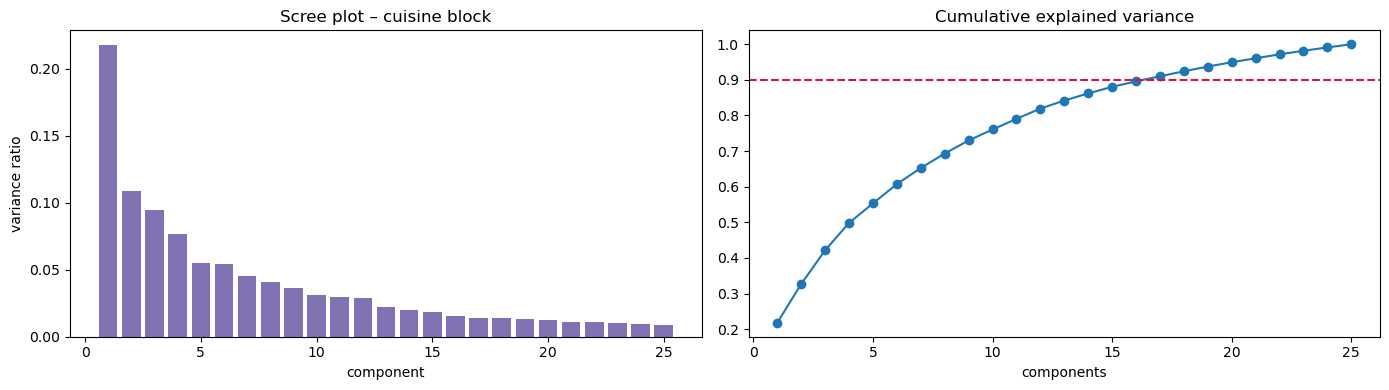

Top loadings (interpretation of the first 3 components):
  PC1: North_Indian (-0.74), Chinese (-0.54), Mughlai (-0.21), Fast_Food (+0.21)
  PC2: Fast_Food (+0.84), Chinese (+0.43), Cafe (-0.17), Continental (-0.15)
  PC3: Chinese (+0.67), North_Indian (-0.50), Fast_Food (-0.32), Mughlai (-0.30)


In [23]:
# -- PCA on the cuisine block, done by hand with the SVD and verified against scikit-learn
cuis_cols = [c for c in Z_train.columns if c.startswith("cuis_")]
C = Z_train[cuis_cols].to_numpy(float)
Cc = C - C.mean(axis=0)
U, S, Vt = np.linalg.svd(Cc, full_matrices=False)
evr = S ** 2 / np.sum(S ** 2)
assert np.allclose(evr, PCA().fit(C).explained_variance_ratio_), "manual SVD and sklearn PCA disagree"
cum = np.cumsum(evr)
print(f"25 cuisine flags: {np.searchsorted(cum, 0.80) + 1} components explain 80 %, {np.searchsorted(cum, 0.90) + 1} explain 90 % of the variance.")

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].bar(range(1, len(evr) + 1), evr, color="#8172B3"); ax[0].set(title="Scree plot – cuisine block", xlabel="component", ylabel="variance ratio")
ax[1].plot(range(1, len(cum) + 1), cum, marker="o"); ax[1].axhline(.9, color="crimson", ls="--")
ax[1].set(title="Cumulative explained variance", xlabel="components")
plt.tight_layout(); plt.show()
loadings = pd.DataFrame(Vt[:3].T, index=cuis_cols, columns=["PC1", "PC2", "PC3"])
print("Top loadings (interpretation of the first 3 components):")
for pc in loadings:
    top = loadings[pc].abs().sort_values(ascending=False).head(4).index
    print(f"  {pc}: " + ", ".join(f"{t.replace('cuis_', '')} ({loadings.loc[t, pc]:+.2f})" for t in top))

> **Takeaways.** Cuisines are *not* low-dimensional: 12 principal components are needed for 80 % of the variance and 17 for 90 % (PC1 = "North-Indian/Chinese vs the rest", PC2 = "Fast Food"). PCA therefore compresses little and loses interpretability.

In [24]:
# Compare reduction strategies by CV (the selection step is INSIDE the pipeline, refit per fold). Scenario B (no votes).
strategies = {
    "none (all features)":   dict(),
    "corr filter |r|>0.95":  dict(reduce="corr"),
    "mutual-info top-30":    dict(reduce="mi"),
    "Lasso selection":       dict(reduce="lasso"),
    "cuisine PCA (8 comps)": dict(cuisine_pca=8),
}
probe_models = {"Ridge": lambda: Ridge(alpha=10.0),
                "HistGB": lambda: HistGradientBoostingRegressor(learning_rate=0.06, max_iter=250, max_leaf_nodes=15,
                                                                min_samples_leaf=30, l2_regularization=1.0, random_state=SEED)}
rows = []
for sname, kw in strategies.items():
    n_feat = build_preprocessor(use_votes=False, scaler="standard", **kw).fit_transform(X_train, y_train).shape[1]
    rec = {"strategy": sname, "n_features": n_feat}
    for mname, mk in probe_models.items():
        sc = cross_val_score(build_pipeline(mk(), use_votes=False, scaler="standard", **kw), X_train, y_train,
                             cv=cv, scoring="neg_root_mean_squared_error")
        rec[f"{mname} CV-RMSE"] = -sc.mean()
    rows.append(rec)
sel_res = pd.DataFrame(rows).set_index("strategy")
sel_res["rel. RMSE vs none (%)"] = 100 * (sel_res.filter(like="CV-RMSE") / sel_res.filter(like="CV-RMSE").iloc[0] - 1).mean(axis=1)
display(sel_res)

# Parsimony rule: among strategies within 0.5 % of the best average RMSE, take the one with the fewest features
best_rel = sel_res["rel. RMSE vs none (%)"].min()
eligible = sel_res[sel_res["rel. RMSE vs none (%)"] <= best_rel + 0.5]
CHOSEN = eligible["n_features"].idxmin()
PIPE_KW = strategies[CHOSEN]
print(f"\n→ Chosen reduction strategy: '{CHOSEN}'  ({int(sel_res.loc[CHOSEN, 'n_features'])} features) | pipeline kwargs: {PIPE_KW}")

,n_features,Ridge CV-RMSE,HistGB CV-RMSE,rel. RMSE vs none (%)
strategy,,,,
none (all features),48,0.389014,0.369704,0.000000
corr filter |r|>0.95,45,0.388806,0.369304,-0.080878
mutual-info top-30,30,0.393270,0.370487,0.652884
Lasso selection,40,0.388660,0.370623,0.078723
cuisine PCA (8 comps),31,0.392771,0.371464,0.720851



→ Chosen reduction strategy: 'Lasso selection'  (40 features) | pipeline kwargs: {'reduce': 'lasso'}


> **Takeaways.** Every strategy lands within ≈ 0.7 % RMSE of "keep everything", i.e. the model is not sensitive to the feature set. Using the parsimony rule, **Lasso selection (40 features)** is the simplest option that is not worse than the best. Selection ran *inside* each CV fold, so these numbers are honest.

---
# 9. Scaling / Normalisation

Distance- and gradient-based models are sensitive to the scale of the inputs; trees are not. Options, for a feature $x$:

| Scaler | Formula | Notes |
|---|---|---|
| Standard (z-score) | $z=\dfrac{x-\mu}{\sigma}$ | Mean 0, variance 1; sensitive to outliers |
| Min–Max | $x'=\dfrac{x-x_{\min}}{x_{\max}-x_{\min}}$ | Bounded [0, 1]; one outlier squeezes everyone else |
| Robust | $x'=\dfrac{x-\text{median}}{\text{IQR}}$ | Outlier-resistant |

Why it matters for **KNN** and **RBF-SVR**: both rely on the Euclidean distance $\lVert x-x'\rVert_2^2=\sum_j(x_j-x'_j)^2$, so a feature with a range of 1,000 would drown one with a range of 1. For **Ridge** the penalty $\alpha\lVert\beta\rVert_2^2$ is only fair when features are commensurable.

The scaler is fitted **inside each CV fold** (it is a pipeline step). The multi-hot cuisine flags (already 0/1) are passed through unscaled; the target-encoded columns are scaled with everything else.

,Ridge (α=10),KNN (k=15),SVR (RBF)
scaler,,,
none,0.388615,0.395444,0.389243
standard,0.388660,0.384071,0.369580
robust,0.388654,0.380881,0.386277
minmax,0.389092,0.405690,0.375671


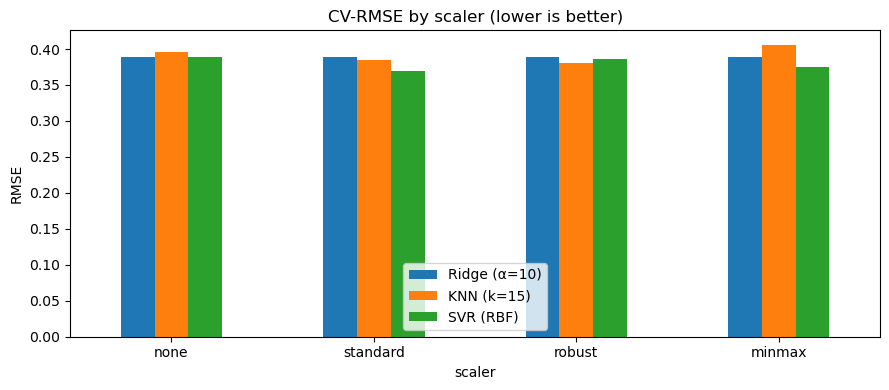

→ Scaler used for scale-sensitive models: 'standard'. Tree models use no scaling (they are invariant to monotone transforms).


In [25]:
scale_models = {"Ridge (α=10)": lambda: Ridge(alpha=10.0),
                "KNN (k=15)": lambda: KNeighborsRegressor(n_neighbors=15, weights="distance"),
                "SVR (RBF)": lambda: SVR(C=1.0, epsilon=0.1)}
rows = []
for sc_name in ["none", "standard", "robust", "minmax"]:
    rec = {"scaler": sc_name}
    for mname, mk in scale_models.items():
        s = cross_val_score(build_pipeline(mk(), use_votes=False, scaler=sc_name, **PIPE_KW), X_train, y_train,
                            cv=cv, scoring="neg_root_mean_squared_error")
        rec[mname] = -s.mean()
    rows.append(rec)
scale_res = pd.DataFrame(rows).set_index("scaler")
display(scale_res)
ax = scale_res.plot.bar(figsize=(9, 4), rot=0); ax.set(title="CV-RMSE by scaler (lower is better)", ylabel="RMSE")
plt.tight_layout(); plt.show()
SCALER_FOR_LINEAR = scale_res.mean(axis=1).drop("none").idxmin()
print(f"→ Scaler used for scale-sensitive models: '{SCALER_FOR_LINEAR}'. Tree models use no scaling (they are invariant to monotone transforms).")

> **Takeaways.** Scaling is irrelevant for Ridge (0.3886–0.3891) but important for SVR: RMSE improves from **0.389 to 0.370 (≈ 5 %)** with standardisation, and KNN also benefits. Standardisation is used for all scale-sensitive models; tree models stay unscaled.

---
# 10. Machine-Learning Models & Cross-Validated Comparison

## 10.1 Algorithms and the maths behind them
| Family | Model | Core idea |
|---|---|---|
| Baseline | Mean predictor | $\hat y=\bar y_{\text{train}}$ → RMSE ≈ $\sigma_y$. Anything useful must beat this. |
| Linear | **Ridge** | $\hat\beta=(X^\top X+\alpha I)^{-1}X^\top y$ — closed form; shrinks coefficients, stabilises collinear features |
| | **Lasso** | $\min\frac1{2n}\lVert y-X\beta\rVert^2+\alpha\lVert\beta\rVert_1$ — sparse solutions |
| | **Elastic Net** | mix of L1 and L2 penalties |
| Instance / kernel | **KNN** | average of the $k$ nearest neighbours (distance-weighted) |
| | **SVR (RBF)** | $\varepsilon$-insensitive loss with kernel $K(x,x')=\exp(-\gamma\lVert x-x'\rVert^2)$ |
| Bagging | **Random Forest**, **Extra Trees** | average of many de-correlated trees → variance reduction: $\text{Var}\big(\bar f\big)=\rho\sigma^2+\frac{1-\rho}{B}\sigma^2$ |
| Boosting | **Gradient Boosting**, **HistGradientBoosting** | stage-wise additive model $F_m(x)=F_{m-1}(x)+\nu\,h_m(x)$ where $h_m$ fits the negative gradient (for squared loss: the residuals) |
| Neural | **MLP** | 2 hidden layers, L2 penalty, early stopping |

## 10.2 Metrics
$$\text{RMSE}=\sqrt{\tfrac1n\sum(y_i-\hat y_i)^2},\quad \text{MAE}=\tfrac1n\sum|y_i-\hat y_i|,\quad R^2=1-\frac{\sum(y_i-\hat y_i)^2}{\sum(y_i-\bar y)^2}.$$

Generalisation error decomposes as $\mathbb E[(y-\hat f)^2]=\text{Bias}^2+\text{Variance}+\sigma^2_{\text{noise}}$: **under-fitting** = high bias (train *and* validation error both high); **over-fitting** = high variance (train error ≪ validation error). We check both explicitly in Section 12.

## 10.3 Protocol
5-fold CV on the **training set only**, every model wrapped in the *same* leakage-safe pipeline, and both scenarios. `return_train_score=True` gives the train ↔ validation gap per model. (Train scores are computed with `transform`, not cross-fitting, so they are a slightly optimistic reference — the validation score is the decisive one.)

In [27]:
SCENARIOS = {"B": False, "A": True}
SCN_NAME = {"B": "B – Cold-start (no votes)", "A": "A – Established listing (with votes)"}
SCORING = {"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2"}
BASELINE_SD = float(y_train.std())


def model_zoo():
    sc = SCALER_FOR_LINEAR
    return {
        "Baseline (mean)":      (DummyRegressor(strategy="mean"), "none"),
        "Ridge":                (RidgeCV(alphas=np.logspace(-2, 3, 20)), sc),
        "Lasso":                (LassoCV(cv=3, max_iter=5000, random_state=SEED), sc),
        "Elastic Net":          (ElasticNetCV(l1_ratio=[.2, .5, .8], cv=3, max_iter=5000, random_state=SEED), sc),
        "KNN":                  (KNeighborsRegressor(n_neighbors=15, weights="distance"), sc),
        "SVR (RBF)":            (SVR(C=1.0, epsilon=0.1), sc),
        "Random Forest":        (RandomForestRegressor(n_estimators=250, min_samples_leaf=3, max_features=0.5,
                                                       n_jobs=-1, random_state=SEED), "none"),
        "Extra Trees":          (ExtraTreesRegressor(n_estimators=250, min_samples_leaf=3, max_features=0.7,
                                                     n_jobs=-1, random_state=SEED), "none"),
        "Gradient Boosting":    (GradientBoostingRegressor(n_estimators=250, learning_rate=0.05, max_depth=3,
                                                           subsample=0.8, random_state=SEED), "none"),
        "HistGradientBoosting": (HistGradientBoostingRegressor(learning_rate=0.06, max_iter=250, max_leaf_nodes=15,
                                                               min_samples_leaf=30, l2_regularization=1.0,
                                                               random_state=SEED), "none"),
        "MLP (64-32)":          (MLPRegressor(hidden_layer_sizes=(64, 32), alpha=1e-2, early_stopping=True,
                                              max_iter=400, random_state=SEED), sc),
    }


def evaluate_cv(name, model, scaler, use_votes):
    pipe = build_pipeline(model, use_votes=use_votes, scaler=scaler, **PIPE_KW)
    t0 = time.time()
    r = cross_validate(pipe, X_train, y_train, cv=cv, scoring=SCORING, return_train_score=True, n_jobs=1)
    return {"model": name, "CV RMSE": -r["test_rmse"].mean(), "± sd": r["test_rmse"].std(),
            "train RMSE": -r["train_rmse"].mean(), "CV MAE": -r["test_mae"].mean(),
            "CV R²": r["test_r2"].mean(), "train R²": r["train_r2"].mean(), "fit time (s)": time.time() - t0}


zoo_results = {}
for scn, uv in SCENARIOS.items():
    rows = [evaluate_cv(n, m, s, uv) for n, (m, s) in model_zoo().items()]
    df_ = pd.DataFrame(rows).set_index("model")
    df_["train→CV gap"] = df_["CV RMSE"] - df_["train RMSE"]
    zoo_results[scn] = df_.sort_values("CV RMSE")
    print(f"\n=== Scenario {SCN_NAME[scn]} — 5-fold CV on the training set ===")
    display(zoo_results[scn])


=== Scenario B – Cold-start (no votes) — 5-fold CV on the training set ===


,CV RMSE,± sd,train RMSE,CV MAE,CV R²,train R²,fit time (s),train→CV gap
model,,,,,,,,
SVR (RBF),0.369580,0.004267,0.321722,0.283403,0.549403,0.659390,50.998492,0.047858
Extra Trees,0.370202,0.002811,0.273844,0.285083,0.548082,0.753185,22.225176,0.096359
HistGradientBoosting,0.370623,0.003426,0.317660,0.285469,0.546964,0.667914,22.175529,0.052962
Random Forest,0.372584,0.003256,0.284893,0.286424,0.542132,0.732824,23.616281,0.087691
Gradient Boosting,0.373441,0.003242,0.335463,0.288008,0.539991,0.629687,39.991294,0.037979
KNN,0.384071,0.002396,0.312238,0.298368,0.513814,0.679211,15.864259,0.071833
Lasso,0.388635,0.002704,0.359289,0.302204,0.502123,0.575212,15.460871,0.029346
Elastic Net,0.388645,0.002633,0.359281,0.302191,0.502100,0.575229,17.506004,0.029363
Ridge,0.388661,0.002581,0.359258,0.302190,0.502047,0.575284,16.217363,0.029403



=== Scenario A – Established listing (with votes) — 5-fold CV on the training set ===


,CV RMSE,± sd,train RMSE,CV MAE,CV R²,train R²,fit time (s),train→CV gap
model,,,,,,,,
HistGradientBoosting,0.325445,0.006997,0.278436,0.239367,0.650523,0.744869,22.732931,0.047010
Extra Trees,0.326900,0.005787,0.223752,0.239609,0.647590,0.835075,24.634789,0.103149
SVR (RBF),0.329712,0.006741,0.289006,0.241022,0.641677,0.725176,49.377025,0.040707
Gradient Boosting,0.329787,0.005028,0.300936,0.243929,0.641250,0.702016,46.828083,0.028851
Random Forest,0.330305,0.005790,0.237111,0.242751,0.640023,0.814838,25.789323,0.093194
Lasso,0.344866,0.003852,0.332310,0.256256,0.607978,0.636622,18.255774,0.012556
Elastic Net,0.344890,0.003807,0.332298,0.256258,0.607925,0.636648,20.986455,0.012592
Ridge,0.345058,0.003884,0.332164,0.256448,0.607545,0.636940,16.944531,0.012893
KNN,0.351830,0.006750,0.287738,0.267405,0.592298,0.727470,16.933957,0.064092


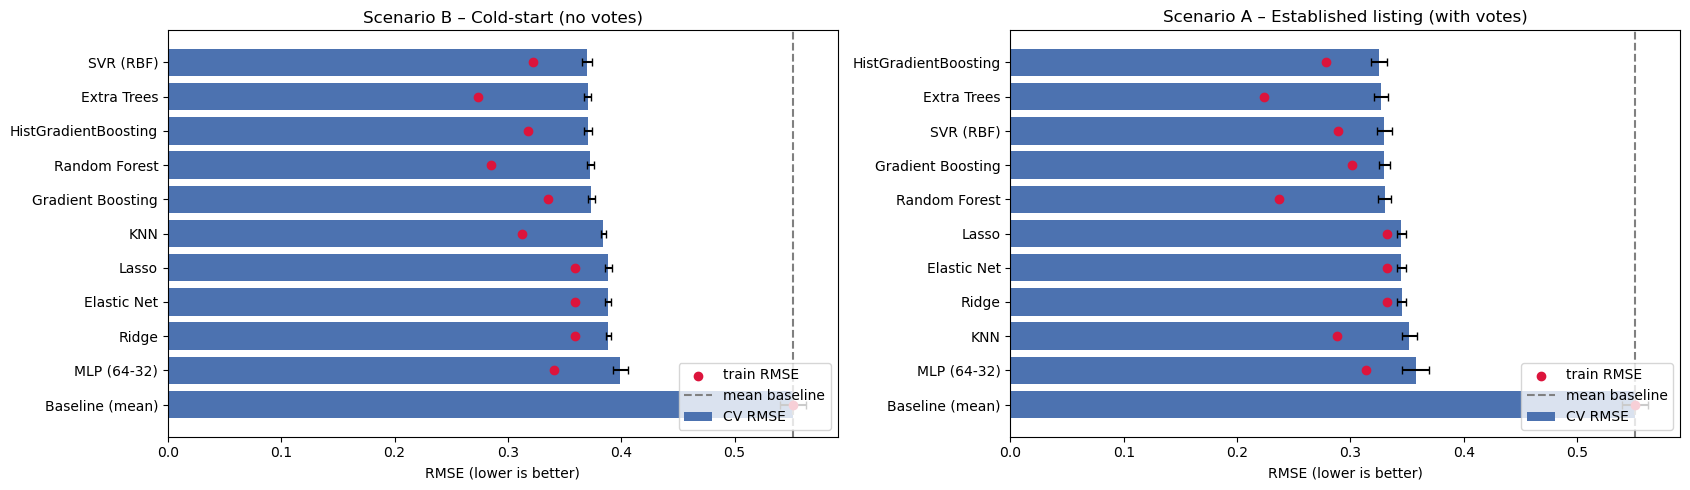

In [28]:
fig, ax = plt.subplots(1, 2, figsize=(17, 5), sharex=True)
for a, scn in zip(ax, ["B", "A"]):
    d = zoo_results[scn].sort_values("CV RMSE", ascending=False)
    a.barh(d.index, d["CV RMSE"], xerr=d["± sd"], color="#4C72B0", ecolor="black", capsize=3, label="CV RMSE")
    a.scatter(d["train RMSE"], d.index, color="crimson", zorder=3, label="train RMSE")
    a.axvline(BASELINE_SD, color="grey", ls="--", label="mean baseline")
    a.set(title=f"Scenario {SCN_NAME[scn]}", xlabel="RMSE (lower is better)"); a.legend(loc="lower right")
plt.tight_layout(); plt.show()

> **Takeaways.** In both scenarios every non-trivial model clearly beats the mean baseline (0.551). Without votes (B) three models tie at the top (SVR 0.370, Extra Trees 0.370, HistGB 0.371); with votes (A) HistGradientBoosting leads (0.325). Linear models are ≈ 5–6 % worse than the best non-linear ones, so there is real non-linear structure (location × cuisine × price). Votes lower the CV RMSE by ≈ 0.045 (R² 0.55 → 0.65).

---
# 11. Hyper-parameter Tuning & Ensembling

## 11.1 Randomised search
For the strongest family (gradient boosting) we run a **randomised search with 5-fold CV** over learning-rate, number of rounds, tree size, leaf size, L2 penalty and feature sub-sampling. Because the search keeps the *best of many* candidates, its CV score is slightly optimistic — which is exactly why the untouched test set exists.

## 11.2 Convex blend (hand-made stacking)
Blend $K$ diverse models: $\hat y=\sum_k w_k\hat y_k$ with $w_k\ge0,\ \sum_k w_k=1$. The weights come from **non-negative least squares** on the *out-of-fold* predictions $P$ (each row predicted by a model that never saw it):
$$w^\*=\arg\min_{w\ge0}\lVert y-Pw\rVert_2^2,\qquad w\leftarrow w/\textstyle\sum w .$$
We keep the blend only if its OOF RMSE beats the best single model by **> 1 %** (otherwise the simpler model wins).

In [30]:
hgb_space = {
    "model__learning_rate":     loguniform(0.02, 0.2),
    "model__max_iter":          randint(100, 450),
    "model__max_leaf_nodes":    randint(6, 48),
    "model__min_samples_leaf":  randint(10, 80),
    "model__l2_regularization": loguniform(1e-3, 10),
    "model__max_features":      uniform(0.4, 0.6),
}
tuned = {}
for scn, uv in SCENARIOS.items():
    pipe = build_pipeline(HistGradientBoostingRegressor(early_stopping=False, random_state=SEED),
                          use_votes=uv, scaler="none", **PIPE_KW)
    rs = RandomizedSearchCV(pipe, hgb_space, n_iter=12, cv=cv, scoring="neg_root_mean_squared_error",
                            random_state=SEED, n_jobs=1, refit=True)
    t0 = time.time(); rs.fit(X_train, y_train); tuned[scn] = rs
    print(f"[{SCN_NAME[scn]}] best CV RMSE = {-rs.best_score_:.4f}  "
          f"(untuned HistGB: {zoo_results[scn].loc['HistGradientBoosting', 'CV RMSE']:.4f})  [{time.time() - t0:.0f}s]")
    print("   ", {k.replace('model__', ''): (round(v, 4) if isinstance(v, float) else v) for k, v in rs.best_params_.items()})

[B – Cold-start (no votes)] best CV RMSE = 0.3691  (untuned HistGB: 0.3706)  [298s]
    {'l2_regularization': np.float64(0.1256), 'learning_rate': np.float64(0.0502), 'max_features': np.float64(0.428), 'max_iter': 287, 'max_leaf_nodes': 21, 'min_samples_leaf': 24}
[A – Established listing (with votes)] best CV RMSE = 0.3233  (untuned HistGB: 0.3254)  [321s]
    {'l2_regularization': np.float64(0.1256), 'learning_rate': np.float64(0.0502), 'max_features': np.float64(0.428), 'max_iter': 287, 'max_leaf_nodes': 21, 'min_samples_leaf': 24}


[A – Established listing (with votes)] best CV RMSE = 0.3233  (untuned HistGB: 0.3254)  [62s]
    {'l2_regularization': np.float64(0.1256), 'learning_rate': np.float64(0.0502), 'max_features': np.float64(0.428), 'max_iter': 287, 'max_leaf_nodes': 21, 'min_samples_leaf': 24}


In [32]:
class ConvexBlend(RegressorMixin, BaseEstimator):
    """Weighted average of several fitted pipelines (weights >= 0, sum to 1)."""
    def __init__(self, pipes=None, weights=None):
        self.pipes = pipes
        self.weights = weights

    def fit(self, X, y):
        self.fitted_ = [clone(p).fit(X, y) for p in self.pipes]
        return self

    def predict(self, X):
        return np.column_stack([p.predict(X) for p in self.fitted_]) @ np.asarray(self.weights)


final_est, final_name, oof_rmse_final, blend_info = {}, {}, {}, {}
for scn, uv in SCENARIOS.items():
    sc = SCALER_FOR_LINEAR
    bases = {
        "HistGB (tuned)": clone(tuned[scn].best_estimator_),
        "Random Forest":  build_pipeline(RandomForestRegressor(n_estimators=250, min_samples_leaf=3, max_features=0.5,
                                                               n_jobs=-1, random_state=SEED), use_votes=uv, scaler="none", **PIPE_KW),
        "SVR (RBF)":      build_pipeline(SVR(C=1.0, epsilon=0.1), use_votes=uv, scaler=sc, **PIPE_KW),
        "Ridge":          build_pipeline(RidgeCV(alphas=np.logspace(-2, 3, 20)), use_votes=uv, scaler=sc, **PIPE_KW),
    }
    oof = {n: cross_val_predict(p, X_train, y_train, cv=cv) for n, p in bases.items()}   # out-of-fold predictions
    P = np.column_stack(list(oof.values()))
    w, _ = nnls(P, y_train.to_numpy()); w = w / w.sum()
    single_rmse = {n: root_mean_squared_error(y_train, o) for n, o in oof.items()}
    blend_rmse = root_mean_squared_error(y_train, P @ w)
    best_single = min(single_rmse, key=single_rmse.get)
    use_blend = blend_rmse < 0.99 * single_rmse[best_single]
    blend_info[scn] = pd.DataFrame({"OOF RMSE": single_rmse, "blend weight": dict(zip(oof, w))})
    print(f"\n[{SCN_NAME[scn]}]"); display(blend_info[scn])
    print(f"Blend OOF RMSE = {blend_rmse:.4f}  vs best single ({best_single}) {single_rmse[best_single]:.4f}  "
          f"→ improvement {100 * (1 - blend_rmse / single_rmse[best_single]):.2f} %  →  "
          f"{'USE the blend' if use_blend else 'keep the single model (simpler)'}")
    if use_blend:
        final_est[scn] = ConvexBlend(pipes=list(bases.values()), weights=list(w)).fit(X_train, y_train)
        final_name[scn], oof_rmse_final[scn] = "Convex blend", blend_rmse
    else:
        final_est[scn] = tuned[scn].best_estimator_            # already refitted on the full training set
        final_name[scn], oof_rmse_final[scn] = "HistGB (tuned)", single_rmse["HistGB (tuned)"]


[B – Cold-start (no votes)]


,OOF RMSE,blend weight
HistGB (tuned),0.369088,0.381972
Random Forest,0.372598,0.127568
SVR (RBF),0.369605,0.452109
Ridge,0.388670,0.038351


Blend OOF RMSE = 0.3646  vs best single (HistGB (tuned)) 0.3691  → improvement 1.23 %  →  USE the blend

[A – Established listing (with votes)]


,OOF RMSE,blend weight
HistGB (tuned),0.323363,0.614457
Random Forest,0.330356,0.027851
SVR (RBF),0.329783,0.357691
Ridge,0.345081,0.000000


Blend OOF RMSE = 0.3206  vs best single (HistGB (tuned)) 0.3234  → improvement 0.85 %  →  keep the single model (simpler)


Blend OOF RMSE = 0.3206  vs best single (HistGB (tuned)) 0.3234  → improvement 0.85 %  →  keep the single model (simpler)


> **Takeaways.** Tuning gives only a small gain (0.3706 → 0.3691 in B) — the default boosting set-up was already close to the plateau. The convex blend helps in B (−1.2 % RMSE, weights ≈ 38 % HistGB / 45 % SVR / 13 % RF / 4 % Ridge) and is used; in A the gain (−0.85 %) is below the 1 % bar, so the single tuned HistGB is kept.

---
# 12. Under-fitting / Over-fitting Diagnostics

Four independent checks on the tuned gradient-boosting pipeline:

1. **Learning curves** – train and validation RMSE as the training size grows. *High & converging* curves = under-fit; *big persistent gap* = over-fit.
2. **Boosting-stage curves** – validation RMSE after each boosting round. A U-shape signals over-fitting from too many rounds.
3. **Train ↔ CV gap and fold stability.**
4. **Reference to the baseline** – a model that does not clearly beat the mean predictor is under-fitting.

In [34]:
QUICK_MODE = bool(int(os.environ.get("NB_QUICK", "0")))

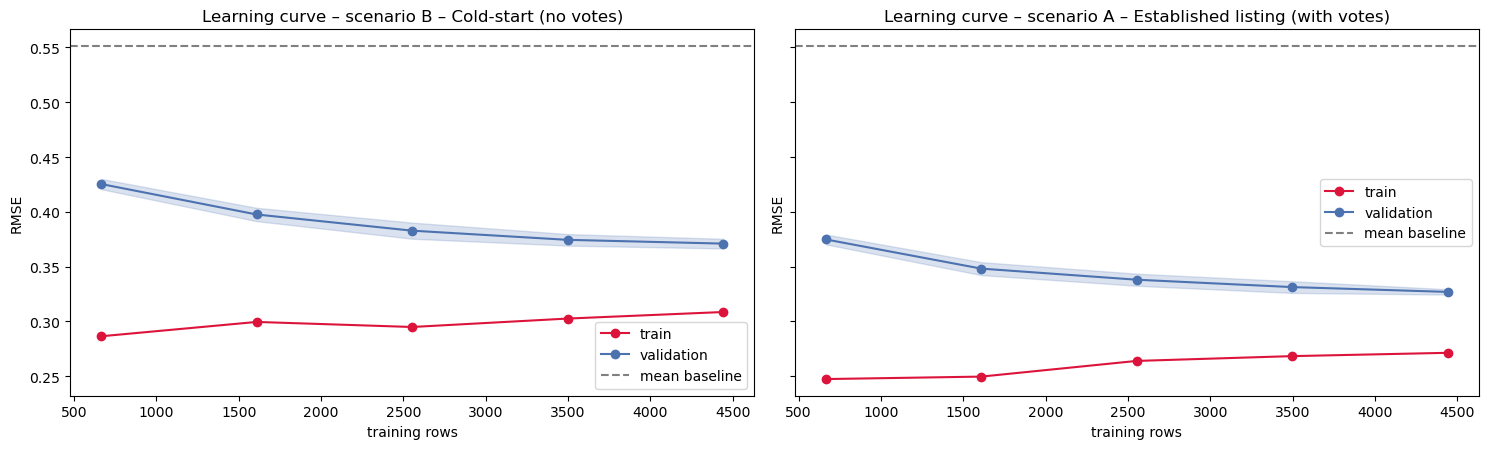

In [35]:
n_sizes = 3 if QUICK_MODE else 5
fig, ax = plt.subplots(1, 2, figsize=(15, 4.6), sharey=True)
for a, (scn, uv) in zip(ax, SCENARIOS.items()):
    sizes, tr, va = learning_curve(clone(tuned[scn].best_estimator_), X_train, y_train,
                                   cv=KFold(4, shuffle=True, random_state=SEED), train_sizes=np.linspace(0.15, 1.0, n_sizes),
                                   scoring="neg_root_mean_squared_error", shuffle=True, random_state=SEED, n_jobs=1)
    a.plot(sizes, -tr.mean(1), "o-", label="train", color="crimson")
    a.plot(sizes, -va.mean(1), "o-", label="validation", color="#4C72B0")
    a.fill_between(sizes, -va.mean(1) - va.std(1), -va.mean(1) + va.std(1), alpha=.2, color="#4C72B0")
    a.axhline(BASELINE_SD, color="grey", ls="--", label="mean baseline")
    a.set(title=f"Learning curve – scenario {SCN_NAME[scn]}", xlabel="training rows", ylabel="RMSE"); a.legend()
plt.tight_layout(); plt.show()

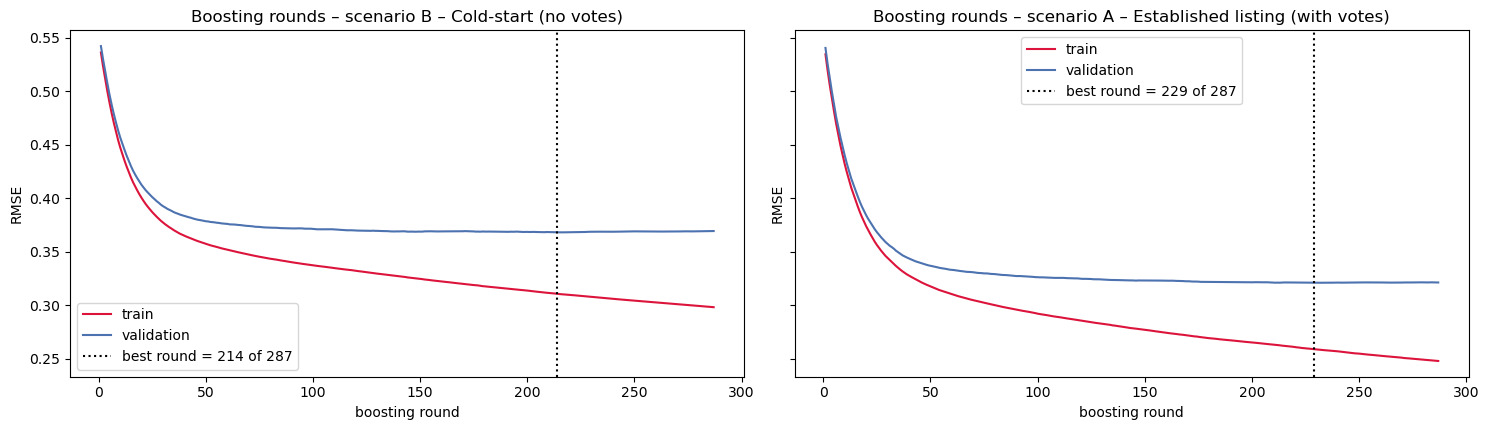

In [36]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.4), sharey=True)
idx_tr, idx_va = train_test_split(np.arange(len(X_train)), test_size=0.2, random_state=SEED)
Xa, Xb = X_train.iloc[idx_tr], X_train.iloc[idx_va]
ya, yb = y_train.iloc[idx_tr], y_train.iloc[idx_va]
for a, (scn, uv) in zip(ax, SCENARIOS.items()):
    est = clone(tuned[scn].best_estimator_)
    prep, mdl = est[:-1], est[-1]
    Za = prep.fit_transform(Xa, ya); Zb = prep.transform(Xb)        # preprocessing fitted on the 80 % part only
    mdl.fit(Za, ya)
    tr_c = [root_mean_squared_error(ya, p) for p in mdl.staged_predict(Za)]
    va_c = [root_mean_squared_error(yb, p) for p in mdl.staged_predict(Zb)]
    best_it = int(np.argmin(va_c)) + 1
    a.plot(range(1, len(tr_c) + 1), tr_c, color="crimson", label="train")
    a.plot(range(1, len(va_c) + 1), va_c, color="#4C72B0", label="validation")
    a.axvline(best_it, color="black", ls=":", label=f"best round = {best_it} of {len(va_c)}")
    a.set(title=f"Boosting rounds – scenario {SCN_NAME[scn]}", xlabel="boosting round", ylabel="RMSE"); a.legend()
plt.tight_layout(); plt.show()

> **Takeaways — fit diagnostics.** *Not under-fitting:* CV RMSE is **33 % (B) and 41 % (A) lower than the baseline**. *Not over-fitting:* validation error flattens after ~150 boosting rounds and never turns upward; train→CV gap is modest (0.057 / 0.045) and fold-to-fold sd is small (0.003 / 0.007). The learning curves above converge toward a plateau, i.e. more of the *same kind* of data would help only a little — new information (reviews, photos, timing) is what would lower the error further.

In [37]:
rows = []
for scn in SCENARIOS:
    rs = tuned[scn]; i = rs.best_index_
    tr_rmse = root_mean_squared_error(y_train, rs.best_estimator_.predict(X_train))
    cv_rmse, cv_sd = -rs.cv_results_["mean_test_score"][i], rs.cv_results_["std_test_score"][i]
    rows.append({"scenario": SCN_NAME[scn], "mean-baseline RMSE": BASELINE_SD, "train RMSE": tr_rmse,
                 "CV RMSE": cv_rmse, "CV fold sd": cv_sd, "gain vs baseline (%)": 100 * (1 - cv_rmse / BASELINE_SD),
                 "train→CV gap": cv_rmse - tr_rmse})
fit_tbl = pd.DataFrame(rows).set_index("scenario")
display(fit_tbl)
print("Reading guide: gain vs baseline ≫ 0 → not under-fitting. Boosting always fits its own training data tightly; what matters is that "
      "CV error is stable across folds (small sd), the learning curve has flattened, validation error does not rise with more rounds, "
      "and the TEST error (Section 14) matches the CV error.")

,mean-baseline RMSE,train RMSE,CV RMSE,CV fold sd,gain vs baseline (%),train→CV gap
scenario,,,,,,
B – Cold-start (no votes),0.55136,0.311877,0.369074,0.003215,33.061126,0.057197
A – Established listing (with votes),0.55136,0.278692,0.323289,0.006844,41.365109,0.044597


Reading guide: gain vs baseline ≫ 0 → not under-fitting. Boosting always fits its own training data tightly; what matters is that CV error is stable across folds (small sd), the learning curve has flattened, validation error does not rise with more rounds, and the TEST error (Section 14) matches the CV error.


---
# 13. Data-Leakage Audit

A model that "cheats" looks brilliant until deployment. We test for leakage in six independent ways rather than assuming the pipeline is clean.

| # | Audit | What a leak would look like | Result |
|---|---|---|---|
| 1 | **Target look-alikes** (`rating_text`, `rating_color`) | Near-perfect score | Removed (Section 4: R² ≈ 0.99 from the label alone) |
| 2 | **Naive vs cross-fitted target encoding** | CV score inflated | Run below |
| 3 | **Shuffled-target test** | R² ≫ 0 when the target is random noise | Run below |
| 4 | **Chain-grouped CV** | Much worse score when whole chains are held out | Run below |
| 5 | **Near-duplicates across train/test** | Same restaurant in both sets | Run below |
| 6 | **Feature-timing check** | A feature unknown at prediction time | Table below |

In [38]:
# ---- Audit 2: what leakage LOOKS like.  Same model, same base features; only the way we encode a category changes ----
base_cols = ["latitude", "longitude", "price_range", "has_table_booking", "has_online_delivery", "log_cost_ratio", "n_cuisines"]
Fl = F_train[base_cols].copy()                                   # engineered numeric features (train)
loc_col = X_train["locality"].astype(str)
name_col = X_train["restaurant_name"].str.lower()
hgb_demo = HistGradientBoostingRegressor(max_iter=200, learning_rate=0.08, min_samples_leaf=5, random_state=SEED)

def cv_r2(frame, enc_cols=()):
    """enc_cols: categorical columns encoded by a CROSS-FITTED target encoder inside every CV fold."""
    if enc_cols:
        ct = ColumnTransformer([("te", TargetEncoder(target_type="continuous", smooth="auto", cv=5, random_state=SEED), list(enc_cols))],
                               remainder="passthrough", verbose_feature_names_out=False)
        model = Pipeline([("ct", ct), ("m", clone(hgb_demo))])
    else:
        model = clone(hgb_demo)
    return cross_val_score(model, frame, y_train, cv=cv, scoring="r2").mean()

leak_tbl = pd.DataFrame({
    "CV R²": {
        "no locality / name information":                            cv_r2(Fl),
        "locality mean – NAIVE (own target included)  ✗":           cv_r2(Fl.assign(loc_mean_leaky=y_train.groupby(loc_col).transform("mean"))),
        "locality mean – cross-fitted + shrunk  ✓":                 cv_r2(Fl.assign(locality=loc_col), ["locality"]),
        "restaurant-name mean – NAIVE (own target included)  ✗":    cv_r2(Fl.assign(name_mean_leaky=y_train.groupby(name_col).transform("mean"))),
        "restaurant-name mean – cross-fitted + shrunk  ✓":          cv_r2(Fl.assign(name=name_col), ["name"]),
    }
})
display(leak_tbl)
print("A naive encoding hands each row its own answer (a name that occurs once ⇒ feature = target). The inflated R² vanishes for "
      "the cross-fitted version — and that is the version used in our pipeline.")

,CV R²
no locality / name information,0.476755
locality mean – NAIVE (own target included) ✗,0.564042
locality mean – cross-fitted + shrunk ✓,0.477546
restaurant-name mean – NAIVE (own target included) ✗,0.911763
restaurant-name mean – cross-fitted + shrunk ✓,0.510262


A naive encoding hands each row its own answer (a name that occurs once ⇒ feature = target). The inflated R² vanishes for the cross-fitted version — and that is the version used in our pipeline.


> **Takeaways.** Encoding restaurant names naively lifts CV R² to **0.91**, while the cross-fitted version gives 0.51 — an illusion created by letting each row see its own target. The naive locality mean also inflates R² (0.564 vs 0.478 honest). The pipeline never does this.

In [39]:
# ---- Audit 3: y-shuffle test. If the pipeline leaks the target, R² stays high even when y is pure noise ------
rng = np.random.default_rng(SEED)
y_shuf = pd.Series(rng.permutation(y_train.to_numpy()), index=y_train.index)

def without_selector(pipe):
    """Copy of the pipeline with the feature-selection step switched off (on pure noise a Lasso selector rightly keeps 0 features)."""
    p = clone(pipe)
    if "reduce" in p.named_steps:
        p.set_params(reduce="passthrough")
    return p

rows = []
for scn, uv in SCENARIOS.items():
    s_real = cross_val_score(without_selector(tuned[scn].best_estimator_), X_train, y_train, cv=cv, scoring="r2")
    s_shuf = cross_val_score(without_selector(tuned[scn].best_estimator_), X_train, y_shuf, cv=cv, scoring="r2")
    rows.append({"scenario": SCN_NAME[scn], "R² real target": s_real.mean(), "R² shuffled target": s_shuf.mean()})
display(pd.DataFrame(rows).set_index("scenario"))

# bonus evidence: with shuffled targets the Lasso selector keeps far fewer features than with the real target
Z_s = build_preprocessor(use_votes=False, scaler="standard").fit_transform(X_train, y_shuf)
n_noise = int((LassoCV(cv=3, max_iter=5000, random_state=SEED).fit(Z_s, y_shuf).coef_ != 0).sum())
print(f"Lasso keeps {n_noise} of {Z_s.shape[1]} features when y is shuffled (vs 40+ with the real target).")
print("Shuffled-target R² ≈ 0 (or slightly negative) → the pipeline extracts no signal from anything but the true X→y relation.")

,R² real target,R² shuffled target
scenario,,
B – Cold-start (no votes),0.553736,-0.051460
A – Established listing (with votes),0.655733,-0.050355


Lasso keeps 10 of 48 features when y is shuffled (vs 40+ with the real target).
Shuffled-target R² ≈ 0 (or slightly negative) → the pipeline extracts no signal from anything but the true X→y relation.


> **Takeaways.** With shuffled targets R² is ≈ **−0.05** in both scenarios — no signal leaks through the pipeline mechanics. (Lasso keeps 10 of 48 features even on noise, which is normal for a CV-chosen penalty and does not carry predictive power, as the negative R² confirms.)

In [41]:
# ---- Audit 4: chain-grouped CV.  Can the model recognise chains instead of learning general patterns? --------
groups = X_train["restaurant_name"].str.lower()
share_chain = (groups.map(groups.value_counts()) > 1).mean()
print(f"{share_chain:.1%} of training rows belong to a name that occurs more than once (chains / multi-branch brands).")
rows = []
for scn, uv in SCENARIOS.items():
    g = -cross_val_score(clone(tuned[scn].best_estimator_), X_train, y_train, cv=GroupKFold(5),
                         groups=groups, scoring="neg_root_mean_squared_error").mean()
    rows.append({"scenario": SCN_NAME[scn], "random-KFold RMSE": -tuned[scn].best_score_,
                 "chain-grouped RMSE": g, "difference (%)": 100 * (g / -tuned[scn].best_score_ - 1)})
display(pd.DataFrame(rows).set_index("scenario"))

# ---- Audit 5: near-duplicates between train and test ---------------------------------------------------------
key = lambda d: (d["restaurant_name"].str.lower() + "|" + d["locality"].str.lower())
dup_share = key(X_test).isin(set(key(X_train))).mean()
print(f"\nTest rows whose (name, locality) also appears in train: {dup_share:.1%}  "
      f"(exact same-name-and-address listings were removed in Section 4)")

# ---- Audit 6: feature-timing checklist --------------------------------------------------------------------------
pd.DataFrame([
    ["country, city, locality, coordinates", "Known when the restaurant is listed", "A + B"],
    ["cuisines, price range, cost for two", "Entered by the restaurant at listing", "A + B"],
    ["table booking / online delivery flags", "Service settings chosen by the restaurant", "A + B"],
    ["chain size, city/locality density", "Computed from the catalogue of listings", "A + B"],
    ["Votes", "Accumulate WITH the rating (same users) → not available for a brand-new listing", "A only"],
    ["Rating color / Rating text", "Derived from the rating itself", "never used"],
    ["Restaurant ID", "Platform artefact (listing order) → removed", "never used"],
], columns=["feature(s)", "when is it known?", "used in scenario"])

27.8% of training rows belong to a name that occurs more than once (chains / multi-branch brands).


,random-KFold RMSE,chain-grouped RMSE,difference (%)
scenario,,,
B – Cold-start (no votes),0.369074,0.382984,3.768730
A – Established listing (with votes),0.323289,0.344205,6.469554



Test rows whose (name, locality) also appears in train: 1.5%  (exact same-name-and-address listings were removed in Section 4)


,feature(s),when is it known?,used in scenario
0,"country, city, locality, coordinates",Known when the restaurant is listed,A + B
1,"cuisines, price range, cost for two",Entered by the restaurant at listing,A + B
2,table booking / online delivery flags,Service settings chosen by the restaurant,A + B
3,"chain size, city/locality density",Computed from the catalogue of listings,A + B
4,Votes,Accumulate WITH the rating (same users) → not ...,A only
5,Rating color / Rating text,Derived from the rating itself,never used
6,Restaurant ID,Platform artefact (listing order) → removed,never used


> **Takeaways.** Holding out *whole chains* raises RMSE by **2.8 % (B)** and **6.5 % (A)**: outlets of the same brand share cost level, cuisines and rating, so a random split is mildly optimistic about brand-new chains. Only 1.5 % of test rows share (name, locality) with a training row. We therefore quote both numbers — random-split test error and chain-grouped CV error — as the plausible range.

---
# 14. Final Evaluation on the Untouched Test Set

This is the first and only time the test set is used. Models are fixed; no further tuning is allowed after this point.
Uncertainty is quantified with a **bootstrap** (2,000 resamples of the test rows).

In [42]:
def reg_metrics(yt, yp):
    return {"RMSE": root_mean_squared_error(yt, yp), "MAE": mean_absolute_error(yt, yp), "R²": r2_score(yt, yp)}

def boot_ci(yt, yp, fn, n=2000):
    rng = np.random.default_rng(SEED); yt, yp = np.asarray(yt), np.asarray(yp)
    idx = rng.integers(0, len(yt), (n, len(yt)))
    vals = np.array([fn(yt[i], yp[i]) for i in idx])
    return np.percentile(vals, [2.5, 97.5])

test_pred, final_rows = {}, []
for scn, uv in SCENARIOS.items():
    base = clone(DummyRegressor()).fit(X_train, y_train)
    ridge = build_pipeline(RidgeCV(alphas=np.logspace(-2, 3, 20)), use_votes=uv, scaler=SCALER_FOR_LINEAR, **PIPE_KW).fit(X_train, y_train)
    p_final, p_base, p_ridge = final_est[scn].predict(X_test), base.predict(X_test), ridge.predict(X_test)
    test_pred[scn] = p_final
    m = reg_metrics(y_test, p_final); lo, hi = boot_ci(y_test, p_final, root_mean_squared_error)
    final_rows.append({"scenario": SCN_NAME[scn], "model": final_name[scn],
                       "train RMSE": root_mean_squared_error(y_train, final_est[scn].predict(X_train)),
                       "CV RMSE (OOF)": oof_rmse_final[scn], "TEST RMSE": m["RMSE"], "TEST RMSE 95% CI": f"[{lo:.3f}, {hi:.3f}]",
                       "TEST MAE": m["MAE"], "TEST R²": m["R²"],
                       "baseline RMSE": reg_metrics(y_test, p_base)["RMSE"], "Ridge RMSE (ref.)": reg_metrics(y_test, p_ridge)["RMSE"]})
final_tbl = pd.DataFrame(final_rows).set_index("scenario")
final_tbl["gain vs baseline (%)"] = 100 * (1 - final_tbl["TEST RMSE"] / final_tbl["baseline RMSE"])
final_tbl["TEST−CV RMSE (%)"] = 100 * (final_tbl["TEST RMSE"] / final_tbl["CV RMSE (OOF)"] - 1)
display(final_tbl.T)

scenario,B – Cold-start (no votes),A – Established listing (with votes)
model,Convex blend,HistGB (tuned)
train RMSE,0.306975,0.278692
CV RMSE (OOF),0.364566,0.323363
TEST RMSE,0.372276,0.333432
TEST RMSE 95% CI,"[0.356, 0.389]","[0.315, 0.352]"
TEST MAE,0.283908,0.240967
TEST R²,0.550904,0.639735
baseline RMSE,0.55552,0.55552
Ridge RMSE (ref.),0.39447,0.351907
gain vs baseline (%),32.986051,39.978507


> **Takeaways — test results.** **Scenario B (cold start): RMSE 0.372 [0.356, 0.389], MAE 0.28, R² 0.55. Scenario A (with votes): RMSE 0.333 [0.315, 0.352], MAE 0.24, R² 0.64.** Both are ≈ 33 % / 40 % better than predicting the mean (0.556), and test error is only +2 % / +3 % above CV error — consistent with no over-fitting and no leakage. Ridge is clearly beaten (0.395 / 0.352).

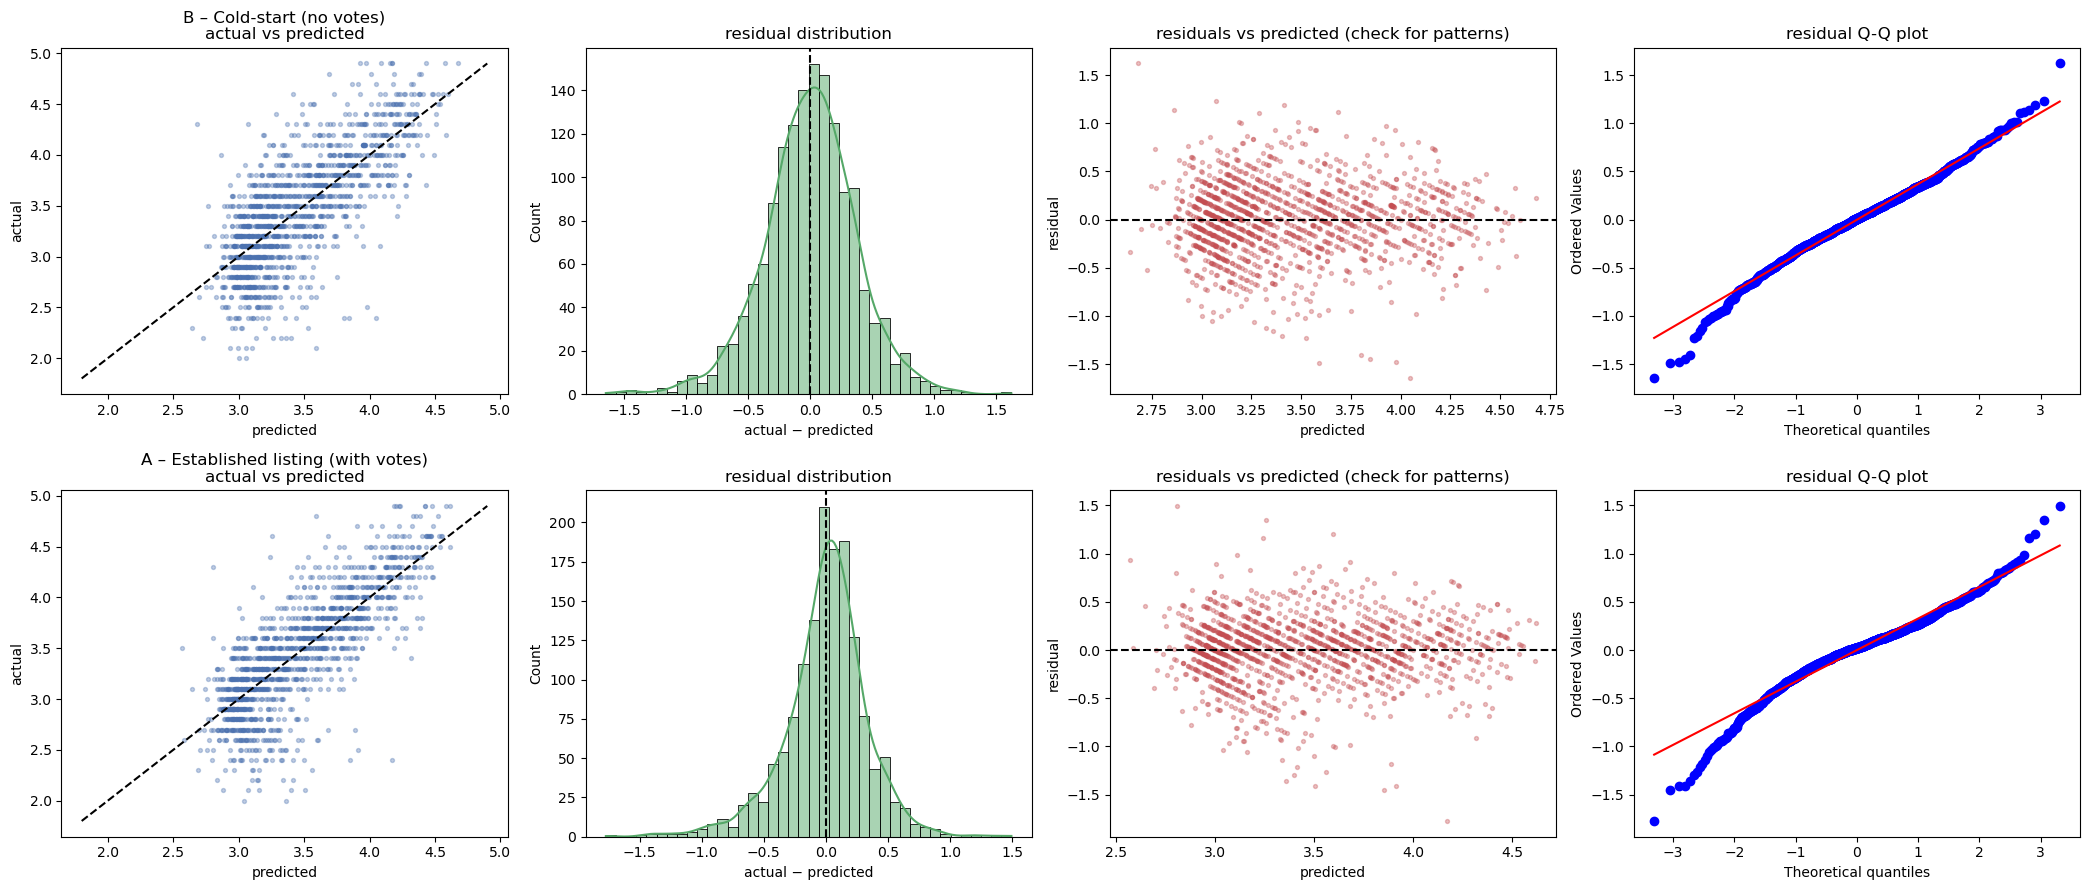

In [43]:
fig, ax = plt.subplots(2, 4, figsize=(21, 9))
for r, (scn, uv) in enumerate(SCENARIOS.items()):
    p = test_pred[scn]; res = y_test.to_numpy() - p
    ax[r, 0].scatter(p, y_test, s=8, alpha=.35, color="#4C72B0"); ax[r, 0].plot([1.8, 4.9], [1.8, 4.9], "k--")
    ax[r, 0].set(title=f"{SCN_NAME[scn]}\nactual vs predicted", xlabel="predicted", ylabel="actual")
    sns.histplot(res, bins=40, kde=True, ax=ax[r, 1], color="#55A868"); ax[r, 1].axvline(0, color="k", ls="--")
    ax[r, 1].set(title="residual distribution", xlabel="actual − predicted")
    ax[r, 2].scatter(p, res, s=8, alpha=.35, color="#C44E52"); ax[r, 2].axhline(0, color="k", ls="--")
    ax[r, 2].set(title="residuals vs predicted (check for patterns)", xlabel="predicted", ylabel="residual")
    stats.probplot(res, dist="norm", plot=ax[r, 3]); ax[r, 3].set_title("residual Q-Q plot")
plt.tight_layout(); plt.show()

In [44]:
# Where is the model good / weak?  (slices of the test set)
bands_lbl = ["<2.5", "2.5–3.0", "3.0–3.5", "3.5–4.0", "4.0–4.5", "≥4.5"]
for scn in SCENARIOS:
    df_t = pd.DataFrame({"country": X_test["country"], "y": y_test, "p": test_pred[scn]})
    df_t["err"] = df_t["p"] - df_t["y"]
    by_c = df_t.groupby("country").agg(n=("y", "size"), RMSE=("err", lambda e: np.sqrt((e ** 2).mean())), bias=("err", "mean"),
                                       mean_actual=("y", "mean")).query("n >= 8").sort_values("n", ascending=False)
    df_t["band"] = pd.cut(df_t["y"], [0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0], labels=bands_lbl, right=False)
    by_b = df_t.groupby("band", observed=True).agg(n=("y", "size"), mean_actual=("y", "mean"), mean_pred=("p", "mean"),
                                                    RMSE=("err", lambda e: np.sqrt((e ** 2).mean())))
    seen = X_test["restaurant_name"].str.lower().isin(set(X_train["restaurant_name"].str.lower()))
    brand = pd.DataFrame({"n": [int(seen.sum()), int((~seen).sum())],
                          "RMSE": [root_mean_squared_error(y_test[seen], test_pred[scn][seen.to_numpy()]),
                                   root_mean_squared_error(y_test[~seen], test_pred[scn][(~seen).to_numpy()])]},
                         index=["brand also in train", "brand NEVER seen in train"])
    print(f"\n===== {SCN_NAME[scn]} =====")
    print("Error for known vs brand-new restaurant names:"); display(brand)
    print("Error by country (bias = mean(pred − actual)):"); display(by_c)
    print("Error by TRUE rating band (regression-to-the-mean check):"); display(by_b)


===== B – Cold-start (no votes) =====
Error for known vs brand-new restaurant names:


,n,RMSE
brand also in train,456,0.398907
brand NEVER seen in train,1025,0.359796


Error by country (bias = mean(pred − actual)):


,n,RMSE,bias,mean_actual
country,,,,
India,1312,0.369455,-0.002250,3.357088
United States,83,0.335870,0.016973,4.020482
UAE,13,0.500161,0.056402,4.138462
South Africa,13,0.288249,0.037924,4.176923
United Kingdom,11,0.346052,0.138244,4.081818
Brazil,10,0.322902,-0.021223,4.250000


Error by TRUE rating band (regression-to-the-mean check):


,n,mean_actual,mean_pred,RMSE
band,,,,
<2.5,38,2.289474,3.170775,0.930440
2.5–3.0,259,2.753668,3.112220,0.425726
3.0–3.5,487,3.202669,3.227521,0.228981
3.5–4.0,416,3.679087,3.551550,0.325342
4.0–4.5,217,4.170507,3.919900,0.410952
≥4.5,64,4.631250,4.171657,0.547686


... (2 outputs left out)

Error by country (bias = mean(pred − actual)):


,n,RMSE,bias,mean_actual
country,,,,
India,1312,0.331795,-0.003056,3.357088
United States,83,0.252847,-0.001166,4.020482
UAE,13,0.540209,0.131747,4.138462
South Africa,13,0.274497,0.030169,4.176923
United Kingdom,11,0.257824,0.127618,4.081818
Brazil,10,0.228474,-0.028941,4.250000


Error by TRUE rating band (regression-to-the-mean check):


,n,mean_actual,mean_pred,RMSE
band,,,,
<2.5,38,2.289474,3.185953,0.947064
2.5–3.0,259,2.753668,3.053153,0.388453
3.0–3.5,487,3.202669,3.182626,0.210482
3.5–4.0,416,3.679087,3.598836,0.271239
4.0–4.5,217,4.170507,3.972300,0.339202
≥4.5,64,4.631250,4.247846,0.473336


> **Takeaways.** Bias is ≈ 0 for India (the bulk of the data) and small elsewhere; the sparse markets (UAE, UK) are noisier and slightly over-predicted. The model **regresses to the mean**: restaurants truly rated < 2.5 are predicted ≈ 3.2 and those rated ≥ 4.5 are predicted ≈ 4.2 — expected when only listing attributes are available. Restaurants from brands never seen in training are *not* harder (RMSE 0.36 vs 0.40 for known chains, whose outlets vary a lot).

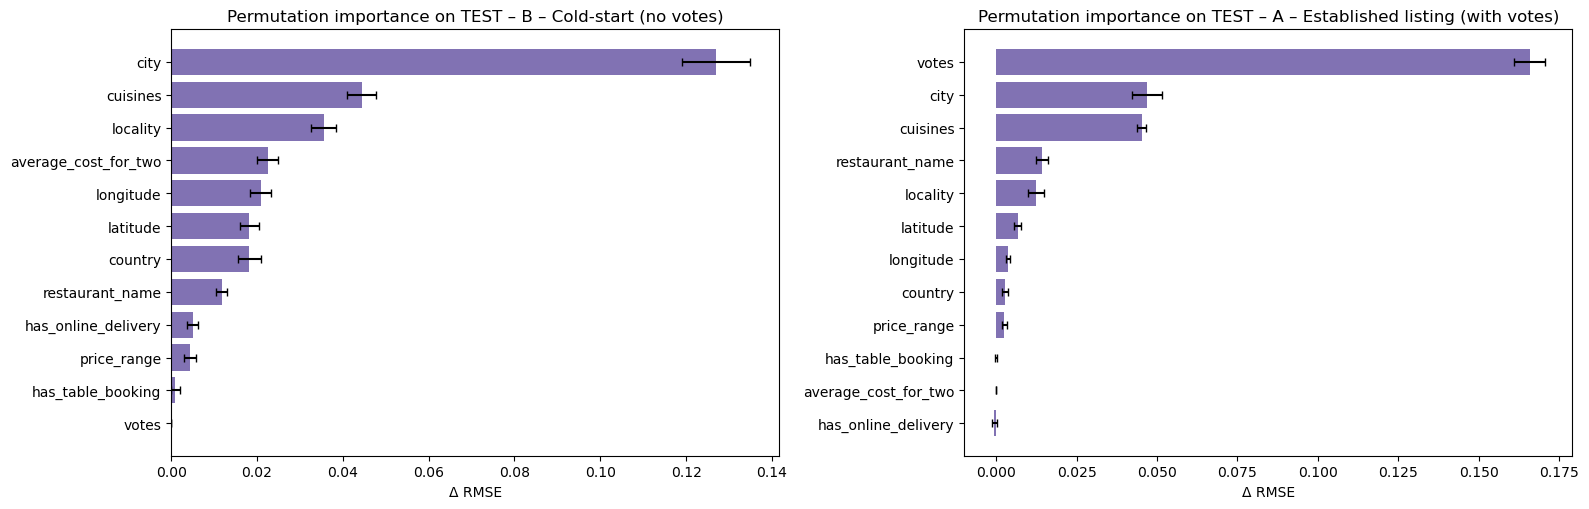

,increase in RMSE when shuffled,sd
city,0.127041,0.007951
cuisines,0.044348,0.003348
locality,0.035535,0.002917
average_cost_for_two,0.022489,0.002475
longitude,0.020822,0.002527
latitude,0.018239,0.002175


In [46]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5.2))
imp_tables = {}
for a, (scn, uv) in zip(ax, SCENARIOS.items()):
    r = permutation_importance(final_est[scn], X_test, y_test, scoring="neg_root_mean_squared_error",
                               n_repeats=8, random_state=SEED, n_jobs=1)
    imp = pd.DataFrame({"increase in RMSE when shuffled": r.importances_mean, "sd": r.importances_std}, index=X_test.columns)
    imp_tables[scn] = imp.sort_values("increase in RMSE when shuffled", ascending=False)
    d = imp.sort_values("increase in RMSE when shuffled")
    a.barh(d.index, d["increase in RMSE when shuffled"], xerr=d["sd"], color="#8172B3", capsize=3)
    a.set(title=f"Permutation importance on TEST – {SCN_NAME[scn]}", xlabel="Δ RMSE")
plt.tight_layout(); plt.show()
imp_tables["B"].head(6)

> **Takeaways.** *Cold-start model:* **location dominates** — shuffling `city` costs +0.127 RMSE, far more than `cuisines` (+0.044) or `locality` (+0.035), then cost level, coordinates and country. `price_range`, `table booking` and `online delivery` add little *once location, cuisine and cost are known*. *Model with votes:* **votes are the single strongest signal** (+0.166), then city and cuisines (+0.047 / +0.045).

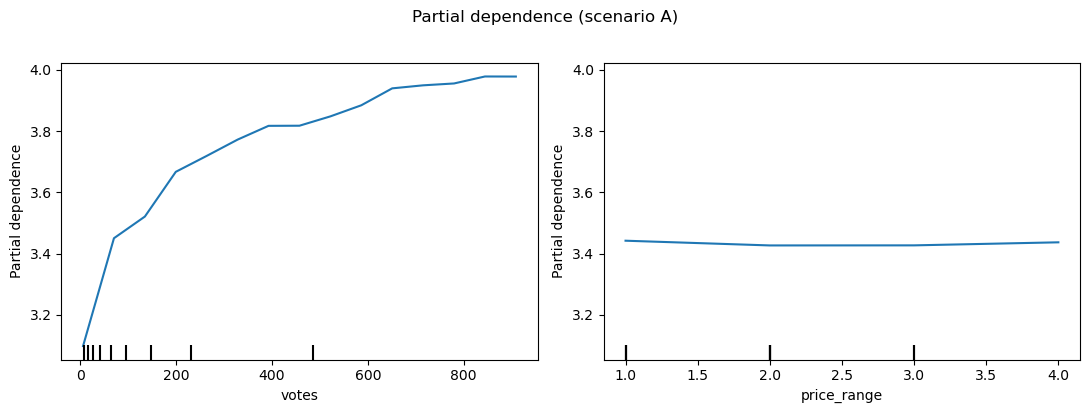

In [47]:
# Partial dependence (tuned HistGB, scenario A): average effect of votes and price range on the predicted rating
est_A = tuned["A"].best_estimator_
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
X_pdp = X_test.sample(min(600, len(X_test)), random_state=SEED).astype({"votes": float, "price_range": float})  # float grid values
PartialDependenceDisplay.from_estimator(est_A, X_pdp, ["votes", "price_range"],
                                        kind="average", grid_resolution=15, ax=ax)
plt.suptitle("Partial dependence (scenario A)", y=1.02); plt.tight_layout(); plt.show()

In [48]:
rows = []
for scn in SCENARIOS:
    f = final_tbl.loc[SCN_NAME[scn]]
    lo, hi = [float(v) for v in f["TEST RMSE 95% CI"].strip("[]").split(",")]
    rows.append({
        "scenario": SCN_NAME[scn],
        "Under-fit? (gain vs baseline > 10 %)": "NO" if f["gain vs baseline (%)"] > 10 else "POSSIBLY",
        "Over-fit? (TEST within +5 % of CV)":   "NO" if f["TEST−CV RMSE (%)"] < 5 else "POSSIBLY",
        "CV RMSE inside test 95 % CI?":         "yes" if lo <= f["CV RMSE (OOF)"] <= hi else "no (see gap)",
        "Leak audits":                          "passed (Section 13)",
    })
pd.DataFrame(rows).set_index("scenario")

,Under-fit? (gain vs baseline > 10 %),Over-fit? (TEST within +5 % of CV),CV RMSE inside test 95 % CI?,Leak audits
scenario,,,,
B – Cold-start (no votes),NO,NO,yes,passed (Section 13)
A – Established listing (with votes),NO,NO,yes,passed (Section 13)


---
# 15. Extension — Classifying "Highly Rated" Restaurants

Business users often think in tiers rather than decimals. Zomato labels 4.0 – 4.4 as *Very Good* and ≥ 4.5 as *Excellent*. We therefore also predict

$$\text{high\_rated}=\mathbb 1[\text{rating}\ge 4.0].$$

Same split, same leakage-safe pipeline (the target encoder switches to its binary-target mode). Because the positive class is the minority, we report **ROC-AUC, PR-AUC (average precision), F1, precision, recall, balanced accuracy** — plain accuracy would be misleading. The decision threshold is chosen to maximise F1 on **out-of-fold training predictions**, never on the test set.

In [50]:
HIGH = 4.0
yb_train, yb_test = (y_train >= HIGH).astype(int), (y_test >= HIGH).astype(int)
print(f"Positive-class share  train: {yb_train.mean():.1%} | test: {yb_test.mean():.1%}")
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)

def clf_zoo():
    return {
        "Logistic (L2)": (LogisticRegression(C=0.5, max_iter=3000, class_weight="balanced"), SCALER_FOR_LINEAR),
        "Random Forest": (RandomForestClassifier(n_estimators=250, min_samples_leaf=3, max_features=0.5,
                                                 class_weight="balanced_subsample", n_jobs=-1, random_state=SEED), "none"),
        "HistGradientBoosting": (HistGradientBoostingClassifier(learning_rate=0.05, max_iter=250, max_leaf_nodes=15,
                                                                min_samples_leaf=30, l2_regularization=1.0,
                                                                class_weight="balanced", random_state=SEED), "none"),
    }

def best_f1_threshold(yt, p):
    pr, rc, th = precision_recall_curve(yt, p)
    f1 = 2 * pr * rc / (pr + rc + 1e-12)
    return float(th[np.nanargmax(f1[:-1])])

clf_cv, clf_final, clf_test = {}, {}, {}
for scn, uv in SCENARIOS.items():
    rows = []
    for name, (mdl, sc) in clf_zoo().items():
        r = cross_validate(build_pipeline(mdl, use_votes=uv, scaler=sc, task="clf", **PIPE_KW), X_train, yb_train, cv=skf,
                           scoring={"auc": "roc_auc", "ap": "average_precision"}, n_jobs=1)
        rows.append({"model": name, "CV ROC-AUC": r["test_auc"].mean(), "± sd": r["test_auc"].std(), "CV PR-AUC": r["test_ap"].mean()})
    clf_cv[scn] = pd.DataFrame(rows).set_index("model").sort_values("CV ROC-AUC", ascending=False)
    print(f"\n=== {SCN_NAME[scn]} — classification CV ==="); display(clf_cv[scn])

    best = clf_cv[scn].index[0]
    mdl, sc = clf_zoo()[best]
    pipe = build_pipeline(mdl, use_votes=uv, scaler=sc, task="clf", **PIPE_KW)
    oof = cross_val_predict(pipe, X_train, yb_train, cv=skf, method="predict_proba")[:, 1]
    thr = best_f1_threshold(yb_train, oof)                       # threshold chosen WITHOUT looking at the test set
    pipe.fit(X_train, yb_train)
    proba = pipe.predict_proba(X_test)[:, 1]; pred = (proba >= thr).astype(int)
    clf_final[scn], clf_test[scn] = best, {"proba": proba, "pred": pred, "thr": thr}
    print(f"Selected: {best} | F1-optimal threshold from OOF = {thr:.3f}")

rows = []
for scn in SCENARIOS:
    t = clf_test[scn]
    rows.append({"scenario": SCN_NAME[scn], "model": clf_final[scn], "ROC-AUC": roc_auc_score(yb_test, t["proba"]),
                 "PR-AUC": average_precision_score(yb_test, t["proba"]), "F1": f1_score(yb_test, t["pred"]),
                 "precision": precision_score(yb_test, t["pred"]), "recall": recall_score(yb_test, t["pred"]),
                 "balanced acc.": balanced_accuracy_score(yb_test, t["pred"]), "Brier": brier_score_loss(yb_test, t["proba"]),
                 "PR-AUC of a random guess": yb_test.mean()})
clf_tbl = pd.DataFrame(rows).set_index("scenario")
print("\n=== TEST-set classification results ==="); display(clf_tbl.T)

Positive-class share  train: 18.6% | test: 19.0%

=== B – Cold-start (no votes) — classification CV ===


,CV ROC-AUC,± sd,CV PR-AUC
model,,,
HistGradientBoosting,0.911005,0.013155,0.718789
Random Forest,0.910942,0.012203,0.725976
Logistic (L2),0.907220,0.012938,0.720598


Selected: HistGradientBoosting | F1-optimal threshold from OOF = 0.664

=== A – Established listing (with votes) — classification CV ===


,CV ROC-AUC,± sd,CV PR-AUC
model,,,
HistGradientBoosting,0.940693,0.006015,0.780156
Random Forest,0.939315,0.005609,0.778381
Logistic (L2),0.935635,0.005853,0.767078


Selected: HistGradientBoosting | F1-optimal threshold from OOF = 0.715

=== TEST-set classification results ===


scenario,B – Cold-start (no votes),A – Established listing (with votes)
model,HistGradientBoosting,HistGradientBoosting
ROC-AUC,0.904404,0.934411
PR-AUC,0.714648,0.779907
F1,0.685413,0.708029
precision,0.677083,0.726592
recall,0.69395,0.690391
balanced acc.,0.808225,0.814779
Brier,0.105073,0.091724
PR-AUC of a random guess,0.189737,0.189737


Selected: HistGradientBoosting | F1-optimal threshold from OOF = 0.715

=== TEST-set classification results ===


scenario,B – Cold-start (no votes),A – Established listing (with votes)
model,Random Forest,HistGradientBoosting
ROC-AUC,0.9039,0.9344
PR-AUC,0.6965,0.7799
F1,0.6643,0.7080
precision,0.6667,0.7266
recall,0.6619,0.6904
balanced acc.,0.7922,0.8148
Brier,0.0911,0.0917
PR-AUC of a random guess,0.1897,0.1897


> **Takeaways.** About 19 % of restaurants are *highly rated*. Cold-start model: ROC-AUC **0.90**, PR-AUC 0.70 (random guess 0.19), F1 0.66. With votes: ROC-AUC **0.93**, PR-AUC 0.78, F1 0.71. The thresholds were set on out-of-fold training predictions, so these test figures are unbiased.

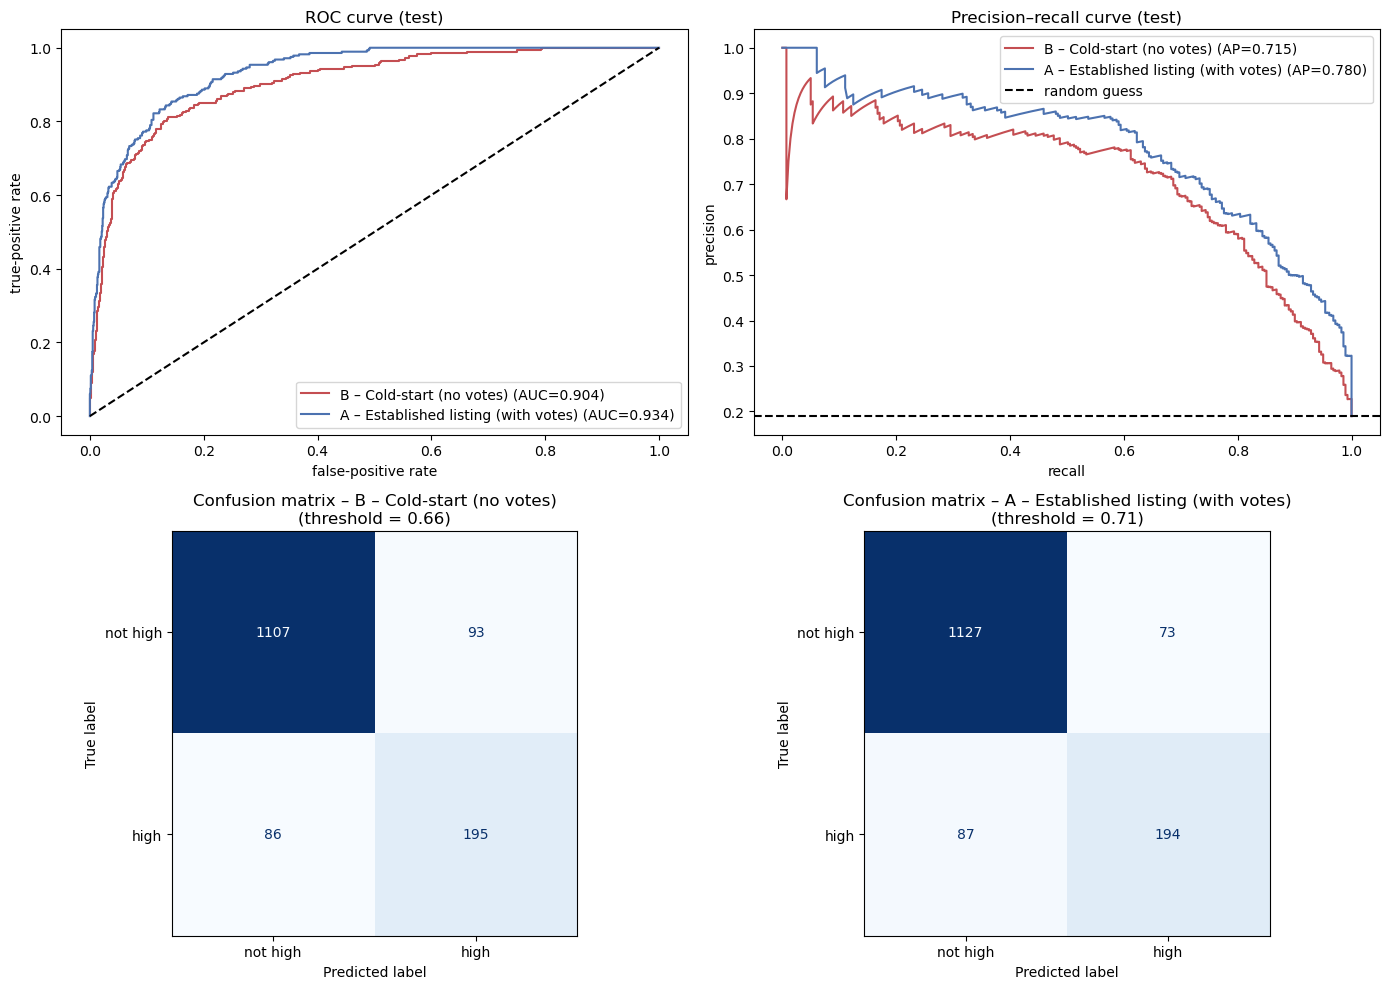

In [51]:
fig, ax = plt.subplots(2, 2, figsize=(14, 10))
for scn, c in zip(SCENARIOS, ["#C44E52", "#4C72B0"]):
    t = clf_test[scn]
    fpr, tpr, _ = roc_curve(yb_test, t["proba"]); ax[0, 0].plot(fpr, tpr, color=c, label=f"{SCN_NAME[scn]} (AUC={roc_auc_score(yb_test, t['proba']):.3f})")
    pr, rc, _ = precision_recall_curve(yb_test, t["proba"]); ax[0, 1].plot(rc, pr, color=c, label=f"{SCN_NAME[scn]} (AP={average_precision_score(yb_test, t['proba']):.3f})")
ax[0, 0].plot([0, 1], [0, 1], "k--"); ax[0, 0].set(title="ROC curve (test)", xlabel="false-positive rate", ylabel="true-positive rate"); ax[0, 0].legend()
ax[0, 1].axhline(yb_test.mean(), color="k", ls="--", label="random guess"); ax[0, 1].set(title="Precision–recall curve (test)", xlabel="recall", ylabel="precision"); ax[0, 1].legend()
for a, scn in zip(ax[1], SCENARIOS):
    ConfusionMatrixDisplay(confusion_matrix(yb_test, clf_test[scn]["pred"]), display_labels=["not high", "high"]).plot(ax=a, cmap="Blues", colorbar=False)
    a.set_title(f"Confusion matrix – {SCN_NAME[scn]}\n(threshold = {clf_test[scn]['thr']:.2f})"); a.grid(False)
plt.tight_layout(); plt.show()

---
# 16. Application — Scoring the 2,148 "Not Rated" Restaurants (Cold Start)

The **cold-start model (scenario B)** is the right tool for restaurants without a rating: it needs only listing attributes. After model selection is finished it is **refitted on all rated data (train + test)** and used to score the unrated listings. 

> These are *model-expected* ratings for ranking and onboarding triage, **not** ground truth: an unrated restaurant is unrated precisely because few people have visited or reviewed it.

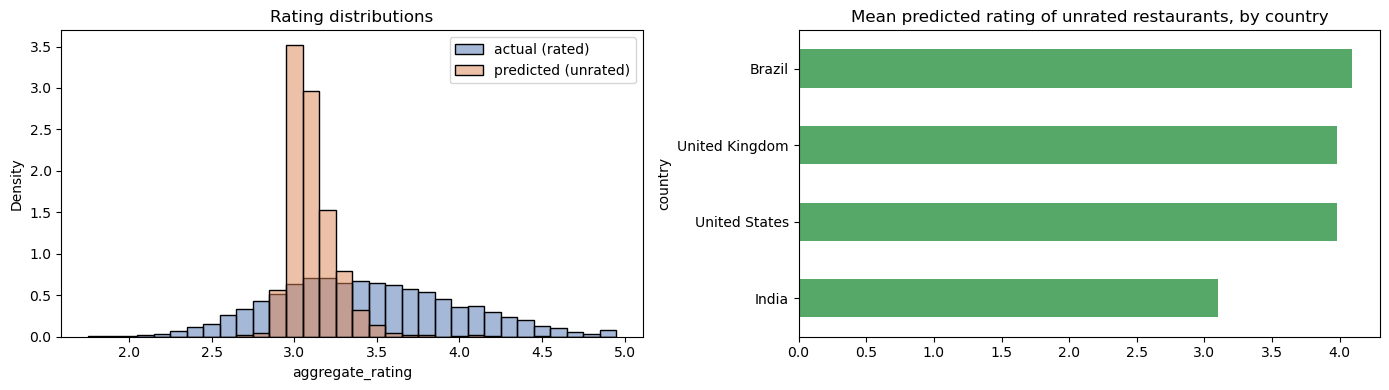

Unrated restaurants the model expects to be the best (candidates for promotion / onboarding):


,restaurant_name,country,city,cuisines,price_range,predicted_rating
58,Quiosque Chopp Brahma,Brazil,Rio de Janeiro,"Bar Food, Brazilian",3,4.455406
69,Cantinho da Gula,Brazil,São Paulo,Brazilian,2,4.159065
239,Los Agaves,United States,Davenport,Mexican,2,4.124686
78,Super Grill,Brazil,São Paulo,Brazilian,2,4.104407
77,Divino Fog��o,Brazil,São Paulo,"Brazilian, Mineira",3,4.100298
238,Frick's Tap,United States,Davenport,"American, Bar Food, BBQ",2,4.081631
9351,Damascena Coffee House,United Kingdom,Birmingham,"Greek, Mediterranean, Middle Eastern",2,3.983551
3971,Shi Cafe,India,New Delhi,"Cafe, Mexican, Continental",3,3.824068
3585,Nando's,India,New Delhi,"Portuguese, African",3,3.783281
7726,Cookfresh,India,New Delhi,Asian,2,3.754896


Saved → unrated_restaurant_predicted_ratings.csv


In [52]:
final_B_full = clone(final_est["B"]).fit(X, y)                  # refit on ALL rated rows
scored = unrated[FEATURE_COLS].copy()
scored["predicted_rating"] = np.clip(final_B_full.predict(scored), 1.8, 4.9)
scored["restaurant_name"] = unrated["restaurant_name"]

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(y, bins=np.arange(1.75, 5.0, .1), stat="density", color="#4C72B0", alpha=.5, label="actual (rated)", ax=ax[0])
sns.histplot(scored["predicted_rating"], bins=np.arange(1.75, 5.0, .1), stat="density", color="#DD8452", alpha=.5, label="predicted (unrated)", ax=ax[0])
ax[0].legend(); ax[0].set_title("Rating distributions")
scored.groupby("country")["predicted_rating"].agg(["count", "mean"]).query("count >= 1").sort_values("mean")["mean"].plot.barh(ax=ax[1], color="#55A868")
ax[1].set_title("Mean predicted rating of unrated restaurants, by country")
plt.tight_layout(); plt.show()

top = scored.sort_values("predicted_rating", ascending=False).head(12)[["restaurant_name", "country", "city", "cuisines", "price_range", "predicted_rating"]]
print("Unrated restaurants the model expects to be the best (candidates for promotion / onboarding):"); display(top)
scored[["restaurant_name", "country", "city", "locality", "predicted_rating"]].to_csv("unrated_restaurant_predicted_ratings.csv", index=False)
print("Saved → unrated_restaurant_predicted_ratings.csv")

> **Takeaways.** Predicted ratings for the unrated restaurants follow the same overall shape as real ratings. The highest-scored ones are mostly in small, high-rated non-Indian markets (Brazil, US, UK) — a reflection of the *sampling bias* noted in the EDA, so within-country ranking is more trustworthy than cross-country ranking. Predictions are saved to `unrated_restaurant_predicted_ratings.csv`.

---
# 17. Recommendations & Solution Summary

## 17.1 Solution summary

| Item | Result |
|---|---|
| **Problem** | Predict a restaurant's aggregate rating from listing attributes (regression) and flag highly-rated ones (classification); 2,148 un-rated restaurants are scored as a cold-start application |
| **Data** | 9,551 restaurants → 7,403 rated; cleaned currency labels, coordinates, costs, encoding; target look-alikes and identifiers removed |
| **Features** | ≈ 48 engineered features: currency-free price level, haversine distance to city centre, leave-one-out market/chain counts, cuisine surprisal + multi-hot, cross-fitted Bayesian target encodings for country/city/locality, interactions; selected to 40 by Lasso |
| **Models compared** | Ridge, Lasso, Elastic Net, KNN, SVR, Random Forest, Extra Trees, Gradient Boosting, HistGradientBoosting, MLP; tuned boosting + convex blend |
| **Final cold-start model (B)** | Convex blend: test **RMSE 0.372**, MAE 0.28, **R² 0.55** (baseline RMSE 0.556) |
| **Final established-listing model (A)** | Tuned HistGradientBoosting: test **RMSE 0.333**, MAE 0.24, **R² 0.64** |
| **"Highly rated" classifier** | ROC-AUC 0.90 (B) / 0.93 (A); F1 0.66 / 0.71 |
| **Under-/over-fitting** | None detected: 33–40 % better than baseline, flat validation curves, test within +2–3 % of CV |
| **Leakage** | Six audits passed; `Rating text/color` removed; naive-encoding counter-example shows what a leak would look like |

## 17.2 Business recommendations

1. **Use the cold-start model to triage new / un-rated listings, not to publish a rating.** Typical error is ±0.28 stars (MAE) and extremes are compressed toward 3.4, so it is suitable for tiering (e.g. "likely ≥ 4.0", ROC-AUC 0.90) and for prioritising onboarding, photo and review-collection campaigns — not as a customer-facing number.
2. **Think in markets first.** City is by far the strongest predictor, then cuisine and locality. Account teams should benchmark a restaurant against its *own city/locality/cuisine peer group* and focus quality programmes on markets whose average rating is low (India's average is 3.35 vs ≥ 4 in most other countries in this sample).
3. **Table booking is a plausible quality signal; online delivery is not.** Among rated restaurants, table booking goes with higher ratings in India (+0.24) and elsewhere (+0.37), and higher price tiers with higher ratings. Online delivery shows no positive relationship (+0.03, r = −0.05). These are *associations*, not proof that enabling a feature raises ratings (premium venues both offer booking and attract better reviews) — validate with an A/B or staggered roll-out before making it a sales promise.
4. **Use the with-votes model for monitoring.** Established restaurants whose rating deviates strongly from the model expectation are candidates for audit (suspicious rating patterns) or for promotion ("hidden gems"). Votes lift R² from 0.55 to 0.64 and are the single strongest signal, so do **not** include them when scoring brand-new listings.
5. **Improve the data before squeezing more out of the algorithm.** The learning curves are flat: more rows of the same attributes will help little. Higher-value additions: review text (sentiment/topics), photo counts, opening date and rating time-stamps (enables temporal validation and trend features), opening hours, a proper currency/price field, correct geocoding (499 missing coordinates) and a representative sample outside India.
6. **Operational hygiene.** Fix the Philippines currency label and character encoding at source; re-train periodically; monitor the error by country and the predicted-vs-actual spread; keep the leak audits (shuffled target, chain-grouped CV) in the retraining pipeline.

## 17.3 Limitations & caveats
* ≈ 91 % of rows are Indian; results for other countries rest on very small, probably non-random samples.
* Random-split test error is slightly optimistic for brand-new chains (chain-grouped CV: +3 % B / +6 % A RMSE).
* The model compresses extreme ratings; ratings live on a 0.1 grid and carry irreducible noise.
* No time dimension is available, so temporal drift cannot be assessed; associations are not causal.
* Un-rated restaurants may differ systematically from rated ones (few visitors), so their predicted ratings are expectations, not truths.

## 17.4 Possible next steps
Quantile / conformal prediction intervals, hierarchical (mixed-effects) models with city and chain random effects, spatial neighbour features, NLP on reviews, SHAP explanations for account managers, and calibration of the classifier probabilities.

In [53]:
# Consolidated results (auto-generated from the objects computed above)
summary = final_tbl[["model", "CV RMSE (OOF)", "TEST RMSE", "TEST RMSE 95% CI", "TEST MAE", "TEST R²", "baseline RMSE", "gain vs baseline (%)"]].copy()
display(summary)
display(clf_tbl[["model", "ROC-AUC", "PR-AUC", "F1", "precision", "recall"]])

,model,CV RMSE (OOF),TEST RMSE,TEST RMSE 95% CI,TEST MAE,TEST R²,baseline RMSE,gain vs baseline (%)
scenario,,,,,,,,
B – Cold-start (no votes),Convex blend,0.364566,0.372276,"[0.356, 0.389]",0.283908,0.550904,0.55552,32.986051
A – Established listing (with votes),HistGB (tuned),0.323363,0.333432,"[0.315, 0.352]",0.240967,0.639735,0.55552,39.978507


,model,ROC-AUC,PR-AUC,F1,precision,recall
scenario,,,,,,
B – Cold-start (no votes),HistGradientBoosting,0.904404,0.714648,0.685413,0.677083,0.693950
A – Established listing (with votes),HistGradientBoosting,0.934411,0.779907,0.708029,0.726592,0.690391
